In [1]:
# ============================================================
# A1 — CONNECT TO THE LOCAL GENERATIVE LLM
# Model: Nemotron3-Nano-4B
# Server: vLLM / Port 8000
# ============================================================

from openai import OpenAI

# Adresse de l'API locale du modèle génératif.
LLM_URL = "http://127.0.0.1:8000/v1"

# Nom exposé par vLLM.
LLM_MODEL = "veltis-llm"

# Création du client avec un délai maximal de 30 secondes.
llm_client = OpenAI(
    base_url=LLM_URL,
    api_key="not-needed",
    timeout=30.0
)

# Demander au serveur la liste des modèles disponibles.
models_available = llm_client.models.list()

print("Modèles disponibles :")

for model in models_available.data:
    print("-", model.id)

# Vérifier que notre modèle est accessible.
assert LLM_MODEL in [
    model.id for model in models_available.data
]

print("\nConnexion LLM : SUCCESS")

Modèles disponibles :
- veltis-llm

Connexion LLM : SUCCESS


In [2]:
# ============================================================
# A2 — FIRST TEXT GENERATION WITH NEMOTRON
# ============================================================

import time

# 1. Define a simple test question.
# No Qdrant retrieval yet.
test_question = "Explique en une phrase ce qu'est un système RAG."

# 2. Start measuring generation time.
start_time = time.perf_counter()

# 3. Send the question to the local LLM.
response = llm_client.chat.completions.create(
    model=LLM_MODEL,
    messages=[
        {
            "role": "system",
            "content": "Réponds en français, en une seule phrase."
        },
        {
            "role": "user",
            "content": test_question
        }
    ],
    temperature=0.2,
    max_tokens=150
)

# 4. Measure elapsed time.
generation_ms = (time.perf_counter() - start_time) * 1000

# 5. Extract the generated answer.
answer = response.choices[0].message.content

# 6. Display the results.
print("QUESTION :", test_question)
print("\nRÉPONSE :", answer)
print(f"\nDurée : {generation_ms:.0f} ms")

# 7. Display token usage, if provided.
if response.usage:
    print("Tokens entrée :", response.usage.prompt_tokens)
    print("Tokens sortie :", response.usage.completion_tokens)

QUESTION : Explique en une phrase ce qu'est un système RAG.

RÉPONSE : L'un des systèmes RAG combine la génération de texte et la récupération d'informations pour fournir des réponses précises et contextuelles.

Durée : 1540 ms
Tokens entrée : 40
Tokens sortie : 30


In [3]:
# ============================================================
# A3 — MODEL INFORMATION AND GENERATION CONFIGURATION
# ============================================================

# 1. Retrieve model information from the supported endpoint.
models = llm_client.models.list()

# 2. Find our active model.
model_info = next(
    (model for model in models.data if model.id == LLM_MODEL),
    None
)

assert model_info is not None, f"Model {LLM_MODEL} not found"

# 3. Display model information.
print("=== MODEL INFORMATION ===")
print("API model ID:", model_info.id)
print("Model architecture:", "NemotronHForCausalLM")
print("Model directory:", "/home/bm/models/nemotron3-nano-4b/vllm")
print("Inference engine:", "vLLM 0.30.0")

# 4. Display generation parameters used in A2.
print("\n=== GENERATION PARAMETERS ===")
print("Temperature:", 0.2)
print("Maximum output tokens:", 150)
print("Maximum context length:", 2048)

# 5. Display measured generation results.
print("\n=== LAST GENERATION ===")
print("Prompt tokens:", response.usage.prompt_tokens)
print("Completion tokens:", response.usage.completion_tokens)
print("Finish reason:", response.choices[0].finish_reason)
print(f"Elapsed time: {generation_ms:.0f} ms")

# 6. Display additional metadata returned by vLLM.
print("\n=== API METADATA ===")
print(model_info.model_dump_json(indent=2))

=== MODEL INFORMATION ===
API model ID: veltis-llm
Model architecture: NemotronHForCausalLM
Model directory: /home/bm/models/nemotron3-nano-4b/vllm
Inference engine: vLLM 0.30.0

=== GENERATION PARAMETERS ===
Temperature: 0.2
Maximum output tokens: 150
Maximum context length: 2048

=== LAST GENERATION ===
Prompt tokens: 40
Completion tokens: 30
Finish reason: stop
Elapsed time: 1540 ms

=== API METADATA ===
{
  "id": "veltis-llm",
  "created": 1792065862,
  "object": "model",
  "owned_by": "vllm",
  "shutdown_date": null,
  "root": "/home/bm/models/nemotron3-nano-4b/vllm",
  "parent": null,
  "max_model_len": 2048,
  "permission": [
    {
      "id": "modelperm-844bc0b16922f2bc",
      "object": "model_permission",
      "created": 1792065862,
      "allow_create_engine": false,
      "allow_sampling": true,
      "allow_logprobs": true,
      "allow_search_indices": false,
      "allow_view": true,
      "allow_fine_tuning": false,
      "organization": "*",
      "group": null,
     

In [4]:
# ============================================================
# A4.2 — VERIFY BOTH LOCAL vLLM SERVICES
# ============================================================

from openai import OpenAI

# 1. Connect to the embedding service.
embedding_client = OpenAI(
    base_url="http://127.0.0.1:8001/v1",
    api_key="not-needed",
    timeout=30.0
)

# 2. Check which models are available on each server.
llm_models = [m.id for m in llm_client.models.list().data]
embedding_models = [m.id for m in embedding_client.models.list().data]

print("=== GENERATIVE LLM ===")
print("Port 8000:", llm_models)

print("\n=== EMBEDDING MODEL ===")
print("Port 8001:", embedding_models)

# 3. Verify that the expected models are available.
assert "veltis-llm" in llm_models, "Nemotron is unavailable"
assert "bge-m3" in embedding_models, "BGE-M3 is unavailable"

# 4. Generate one test embedding.
test_embedding = embedding_client.embeddings.create(
    model="bge-m3",
    input="Quelle est la procédure d'accueil chez Veltis ?"
)

vector = test_embedding.data[0].embedding

print("\n=== EMBEDDING TEST ===")
print("Vector dimensions:", len(vector))

assert len(vector) == 1024, "Unexpected embedding dimensions"

print("\nA4.2 — SUCCESS: Both models are operational.")

=== GENERATIVE LLM ===
Port 8000: ['veltis-llm']

=== EMBEDDING MODEL ===
Port 8001: ['bge-m3']

=== EMBEDDING TEST ===
Vector dimensions: 1024

A4.2 — SUCCESS: Both models are operational.


In [5]:
# ============================================================
# B1 — CONNECT TO QDRANT AND INSPECT THE EXISTING COLLECTION
# ============================================================

from qdrant_client import QdrantClient

# 1. Connect to the existing local Qdrant server.
qclient = QdrantClient(
    url="http://127.0.0.1:6333",
    api_key="1234",
    timeout=30
)

# 2. Select the existing 100-token hybrid collection.
COLLECTION_NAME = "veltis_hybrid_100_20261014"

# 3. Check that the collection exists.
assert qclient.collection_exists(COLLECTION_NAME), (
    f"Collection not found: {COLLECTION_NAME}"
)

# 4. Retrieve collection information.
collection_info = qclient.get_collection(COLLECTION_NAME)

# 5. Display the configuration.
print("=== QDRANT COLLECTION ===")
print("Name:", COLLECTION_NAME)
print("Status:", collection_info.status)
print("Points:", collection_info.points_count)

print("\n=== DENSE VECTOR CONFIGURATION ===")
print(collection_info.config.params.vectors)

print("\n=== SPARSE VECTOR CONFIGURATION ===")
print(collection_info.config.params.sparse_vectors)

print("\nB1 — Collection found successfully.")


=== QDRANT COLLECTION ===
Name: veltis_hybrid_100_20261014
Status: green
Points: 129

=== DENSE VECTOR CONFIGURATION ===
{'dense': VectorParams(size=1024, distance=<Distance.COSINE: 'Cosine'>, hnsw_config=None, quantization_config=None, on_disk=None, memory=None, datatype=None, multivector_config=None)}

=== SPARSE VECTOR CONFIGURATION ===
{'sparse': SparseVectorParams(index=None, modifier=<Modifier.IDF: 'idf'>)}

B1 — Collection found successfully.


/tmp/ipykernel_297670/4246474725.py:8: UserWarning: Api key is used with an insecure connection.
  qclient = QdrantClient(


In [6]:
# ============================================================
# B2 — INSPECT EXISTING QDRANT POINTS AND METADATA
# ============================================================

# Retrieve 3 existing points without modifying the collection.
points, next_offset = qclient.scroll(
    collection_name=COLLECTION_NAME,
    limit=3,
    with_payload=True,
    with_vectors=False
)

print("=== SAMPLE POINTS ===")

for i, point in enumerate(points, start=1):
    print(f"\n--- POINT {i} ---")
    print("Qdrant ID:", point.id)

    # Display available metadata fields.
    payload = point.payload or {}
    print("Payload fields:", list(payload.keys()))

    # Display metadata values, truncating long text fields.
    for key, value in payload.items():
        value_str = str(value)
        if len(value_str) > 250:
            value_str = value_str[:250] + "..."
        print(f"{key}: {value_str}")

print("\nB2 — Inspection completed.")


=== SAMPLE POINTS ===

--- POINT 1 ---
Qdrant ID: 0428088e-f2f8-5315-bf6a-1bf9bbe4267a
Payload fields: ['dataset', 'chunk_profile', 'file_name', 'global_index', 'text']
dataset: veltis
chunk_profile: 100
file_name: rapport_annuel_2025.pdf
global_index: 111
text: 6. Détail des investissements 2025
Le tableau suivant liste l'ensemble des investissements engagés en 2025, par service.

--- POINT 2 ---
Qdrant ID: 0713a9e1-e03b-53bb-b866-7da52eba04c5
Payload fields: ['dataset', 'chunk_profile', 'file_name', 'global_index', 'text']
dataset: veltis
chunk_profile: 100
file_name: plan_strategique_2026-2028.pptx
global_index: 52
text: Plan stratégique « Cap 2028 »
Comité de direction — janvier 2026
Où en sommes-nous ?
38,4 M€
9 850
27 %
chiffre d'affaires 2025
vélos vendus en 2025
du chiffre d'affaires à l'export
Veltis SA — Comité de direction — confidentiel
Trois axes stratégiqu...

--- POINT 3 ---
Qdrant ID: 0747cdcf-d735-50cf-84e8-e3c7b0cfa86e
Payload fields: ['dataset', 'chunk_profile', 'fil

In [7]:
# ============================================================
# B3 — HYBRID RETRIEVAL: DENSE + BM25 + RRF
# ============================================================

from qdrant_client import models

# 1. Question test provenant de nos exercices Veltis.
question = "Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?"

# 2. Convertir la question en vecteur dense avec BGE-M3.
embedding_response = embedding_client.embeddings.create(
    model="bge-m3",
    input=question
)

question_vector = embedding_response.data[0].embedding

# 3. Paramètres de recherche.
TOP_K = 5
PREFETCH_LIMIT = 30
RRF_K = 60
RRF_WEIGHTS = [2.0, 1.0]

# 4. Recherche hybride dans Qdrant.
results = qclient.query_points(
    collection_name=COLLECTION_NAME,

    prefetch=[
        # Recherche sémantique : vecteur dense BGE-M3.
        models.Prefetch(
            query=question_vector,
            using="dense",
            limit=PREFETCH_LIMIT
        ),

        # Recherche lexicale : BM25.
        models.Prefetch(
            query=models.Document(
                text=question,
                model="qdrant/bm25"
            ),
            using="sparse",
            limit=PREFETCH_LIMIT
        )
    ],

    # Fusion des deux classements.
    query=models.RrfQuery(
        rrf=models.Rrf(
            k=RRF_K,
            weights=RRF_WEIGHTS
        )
    ),

    limit=TOP_K,
    with_payload=True
)

# 5. Afficher les cinq passages retrouvés.
print("QUESTION :", question)
print("\n=== TOP 5 HYBRID RESULTS ===")

for rank, point in enumerate(results.points, start=1):
    payload = point.payload or {}

    print(f"\n--- RESULT {rank} ---")
    print("Score RRF:", round(point.score, 5))
    print("Document:", payload.get("file_name"))
    print("Chunk:", payload.get("global_index"))
    print("Point ID:", point.id)
    print("Text:", payload.get("text", "")[:500])
    

QUESTION : Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?

=== TOP 5 HYBRID RESULTS ===

--- RESULT 1 ---
Score RRF: 0.03347
Document: guide_onboarding.pdf
Chunk: 13
Point ID: 2c81fdfb-d150-541d-b436-79773d8c60bb
Text: 1. Bienvenue chez Veltis
Ce guide rassemble tout ce qu'il faut savoir pour vos premières semaines. Il ne remplace pas les échanges avec votre manager et votre parrain ou marraine : n'hésitez jamais à poser des questions. - Sophie Marchal, directrice des ressources humaines

--- RESULT 2 ---
Score RRF: 0.03229
Document: guide_onboarding.pdf
Chunk: 19
Point ID: 5017f1d7-de13-5fb1-8eff-30dd7142f82f
Text: 3.3 Accès informatiques
Votre compte est créé par le service IT avant votre arrivée. Le mot de passe provisoire doit être changé dans les 24 heures, faute de quoi le compte est bloqué. En cas de problème, appelez le helpdesk au poste 2100 ou écrivez à helpdesk@veltis.example.

--- RESULT 3 ---
Score RRF: 0.01653
Document: presentation_veltis.pdf

In [8]:
# ============================================================
# B4 — BUILD DOCUMENTARY CONTEXT FOR THE LLM
# ============================================================

# 1. Verify that the previous retrieval returned passages.
assert results.points, "No retrieved passages available."

# 2. Create a list to store formatted passages.
context_parts = []

# 3. Format each retrieved passage with its metadata.
for rank, point in enumerate(results.points, start=1):

    # Retrieve the metadata stored in Qdrant.
    payload = point.payload or {}

    # Assign a citation identifier.
    citation_id = f"S{rank}"

    # Retrieve source information.
    document = payload.get("file_name", "unknown")
    chunk_id = payload.get("global_index", "unknown")
    text = payload.get("text", "")

    # Build a traceable context block.
    passage = (
        f"[{citation_id}]\n"
        f"Document: {document}\n"
        f"Chunk ID: {chunk_id}\n"
        f"Rank: {rank}\n"
        f"Qdrant Point ID: {point.id}\n"
        f"Text:\n{text}"
    )

    context_parts.append(passage)

# 4. Combine all passages into one context.
rag_context = "\n\n---\n\n".join(context_parts)

# 5. Display the context.
print("=== RAG CONTEXT ===")
print(rag_context)

print(f"\nB4 — SUCCESS: {len(context_parts)} passages prepared.")

=== RAG CONTEXT ===
[S1]
Document: guide_onboarding.pdf
Chunk ID: 13
Rank: 1
Qdrant Point ID: 2c81fdfb-d150-541d-b436-79773d8c60bb
Text:
1. Bienvenue chez Veltis
Ce guide rassemble tout ce qu'il faut savoir pour vos premières semaines. Il ne remplace pas les échanges avec votre manager et votre parrain ou marraine : n'hésitez jamais à poser des questions. - Sophie Marchal, directrice des ressources humaines

---

[S2]
Document: guide_onboarding.pdf
Chunk ID: 19
Rank: 2
Qdrant Point ID: 5017f1d7-de13-5fb1-8eff-30dd7142f82f
Text:
3.3 Accès informatiques
Votre compte est créé par le service IT avant votre arrivée. Le mot de passe provisoire doit être changé dans les 24 heures, faute de quoi le compte est bloqué. En cas de problème, appelez le helpdesk au poste 2100 ou écrivez à helpdesk@veltis.example.

---

[S3]
Document: presentation_veltis.pdf
Chunk ID: 80
Rank: 3
Qdrant Point ID: 099ee613-fab4-5713-ac82-fb370b96739c
Text:
Présentation de l'entreprise
Veltis SA - édition 2026

---

[S4

In [9]:
# ============================================================
# B5 — GENERATE A DOCUMENT-GROUNDED ANSWER WITH CITATIONS
# ============================================================

import time

# 1. Instructions defining how the LLM must use the documents.
RAG_SYSTEM_PROMPT = """
Tu es un assistant documentaire interne de Veltis.

Règles obligatoires :
1. Réponds uniquement à partir des passages fournis.
2. N'utilise pas tes connaissances générales pour compléter les informations.
3. Cite les passages qui justifient ta réponse : [S1], [S2], etc.
4. N'invente jamais de références ou d'informations.
5. Si les passages ne permettent pas de répondre, écris :
   "Je ne trouve pas cette information dans les documents Veltis disponibles."
6. Réponds en français, de façon concise et précise.
"""

# 2. Combine the question and retrieved documentary evidence.
RAG_USER_PROMPT = f"""
QUESTION :
{question}

DOCUMENTS DISPONIBLES :
{rag_context}

Réponds à la question en utilisant uniquement les documents ci-dessus.
"""

# 3. Measure generation time.
start_time = time.perf_counter()

# 4. Send the question and evidence to Nemotron.
rag_response = llm_client.chat.completions.create(
    model=LLM_MODEL,
    messages=[
        {"role": "system", "content": RAG_SYSTEM_PROMPT},
        {"role": "user", "content": RAG_USER_PROMPT}
    ],
    temperature=0.1,
    max_tokens=200
)

generation_ms = (time.perf_counter() - start_time) * 1000

# 5. Extract the answer.
rag_answer = rag_response.choices[0].message.content

# 6. Display results.
print("=== QUESTION ===")
print(question)

print("\n=== RAG ANSWER ===")
print(rag_answer)

print("\n=== GENERATION METRICS ===")
print(f"Generation time: {generation_ms:.0f} ms")
print("Prompt tokens:", rag_response.usage.prompt_tokens)
print("Completion tokens:", rag_response.usage.completion_tokens)
print("Finish reason:", rag_response.choices[0].finish_reason)

=== QUESTION ===
Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?

=== RAG ANSWER ===
Je dois répondre à la question : "Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?" En utilisant uniquement les documents fournis.

Regardez les documents :

[S4] : "3.1 Accueil : Présentez-vous à 8 h 30 à l'accueil du bâtiment A. Votre badge d'accès vous y sera remis. Il ouvre les bâtiments, le parking vélo couvert et les distributeurs de la cafétéria."

Cela donne l'heure et le lieu : 8 h 30, bâtiment A.

[S1] parle de bienvenue, mais pas d'heure ou lieu.

[S2] parle d'accès informatiques, pas d'accueil.

[S3] est une présentation de l'entreprise, pas d'accueil.

[S5] est une FAQ sur les congés, pas d'accueil.

Donc la réponse est : 8 h 30, bâtiment A.

Je

=== GENERATION METRICS ===
Generation time: 9727 ms
Prompt tokens: 776
Completion tokens: 200
Finish reason: length


In [10]:
# ============================================================
# B5.1 — TEST DIRECT ANSWER WITHOUT EXPLANATORY REASONING
# ============================================================

import time

# Instructions renforcées pour une réponse documentaire directe.
DIRECT_SYSTEM_PROMPT = """
Tu es l'assistant documentaire de Veltis.

Réponds uniquement à partir des passages fournis.

Consignes :
- Donne directement la réponse finale.
- Ne décris pas ton raisonnement.
- Ne répète pas la question.
- Cite la source utilisée au format [S1], [S2], etc.
- N'invente aucune information.
- Si la réponse est absente des documents, indique :
  "Je ne trouve pas cette information dans les documents Veltis disponibles."

La réponse doit tenir en une ou deux phrases.
"""

start_time = time.perf_counter()

direct_response = llm_client.chat.completions.create(
    model=LLM_MODEL,
    messages=[
        {"role": "system", "content": DIRECT_SYSTEM_PROMPT},
        {
            "role": "user",
            "content": f"""
Question : {question}

Passages documentaires :
{rag_context}

Fournis uniquement la réponse finale.
"""
        }
    ],
    temperature=0.1,
    max_tokens=300
)

direct_generation_ms = (time.perf_counter() - start_time) * 1000

direct_answer = direct_response.choices[0].message.content

print("=== DIRECT RAG ANSWER ===")
print(direct_answer)

print("\n=== METRICS ===")
print("Generation time:", round(direct_generation_ms), "ms")
print("Completion tokens:", direct_response.usage.completion_tokens)
print("Finish reason:", direct_response.choices[0].finish_reason)

=== DIRECT RAG ANSWER ===
Je dois répondre à la question : "Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?"  
Je dois me baser uniquement sur les passages fournis.  
Je ne peux pas inventer d'informations.  
Je dois donner la réponse finale en une ou deux phrases, avec la source citée au format [S1], [S2], etc.  
Je ne peux pas répéter la question.  
Je ne peux pas décrire mon raisonnement.  

Regardons les passages :  
[S4] : "3.1 Accueil : Présentez-vous à 8 h 30 à l'accueil du bâtiment A. Votre badge d'accès vous y sera remis. Il ouvre les bâtiments, le parking vélo couvert et les distributeurs de la cafétéria."  
Cela donne l'heure et le lieu : 8 h 30, bâtiment A, accueil.  
[S1] parle de bienvenue, mais pas d'heure ou lieu.  
[S2] parle d'accès informatiques, pas d'accueil.  
[S3] est une présentation de l'entreprise, pas d'accueil.  
[S5] est une FAQ sur les congés, pas d'accueil.  

Donc la réponse est : "Vous devez vous présenter à 8 h 30 à l'accuei

In [11]:
# ============================================================
# B5.2 — DISABLE NEMOTRON THINKING MODE
# ============================================================

import time

start_time = time.perf_counter()

# Reuse the existing documentary context from B4.
no_thinking_response = llm_client.chat.completions.create(
    model=LLM_MODEL,

    messages=[
        {
            "role": "system",
            "content": DIRECT_SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                f"Question : {question}\n\n"
                f"Passages documentaires :\n{rag_context}\n\n"
                "Fournis uniquement la réponse finale."
            )
        }
    ],

    # Disable reasoning through the model's chat template.
    extra_body={
        "chat_template_kwargs": {
            "enable_thinking": False
        }
    },

    temperature=0,
    max_tokens=120
)

elapsed_ms = (time.perf_counter() - start_time) * 1000

answer = no_thinking_response.choices[0].message.content

print("=== RAG ANSWER — THINKING DISABLED ===")
print(answer)

print("\n=== METRICS ===")
print("Generation time:", round(elapsed_ms), "ms")
print("Completion tokens:", no_thinking_response.usage.completion_tokens)
print("Finish reason:", no_thinking_response.choices[0].finish_reason)

=== RAG ANSWER — THINKING DISABLED ===
Vous devez vous présenter à 8 h 30 à l'accueil du bâtiment A. [S4]

=== METRICS ===
Generation time: 1265 ms
Completion tokens: 25
Finish reason: stop


In [12]:
# ============================================================
# C1 — VALIDATE CITATION IDENTIFIERS
# ============================================================

import re

# 1. Extract citation identifiers from the generated answer.
# Example: "[S5]" -> "S5"
cited_ids = re.findall(r"\[(S\d+)\]", answer)

# 2. Build the set of valid citation identifiers
# from the passages actually retrieved in B3.
valid_ids = {
    f"S{i}"
    for i in range(1, len(results.points) + 1)
}

# 3. Identify citations that do not exist.
invalid_ids = set(cited_ids) - valid_ids

# 4. Display the validation report.
print("=== CITATION VALIDATION ===")
print("Citations in answer:", cited_ids)
print("Available sources:", sorted(valid_ids))
print("Invalid citations:", sorted(invalid_ids))

# 5. Check whether the answer references existing sources.
citations_valid = bool(cited_ids) and not invalid_ids

print("\nCitation existence valid:", citations_valid)

assert citations_valid, "Missing or invented citation identifiers."

=== CITATION VALIDATION ===
Citations in answer: ['S4']
Available sources: ['S1', 'S2', 'S3', 'S4', 'S5']
Invalid citations: []

Citation existence valid: True


In [13]:
# ============================================================
# C2 — VALIDATE FACTUAL SUPPORT FROM CITED PASSAGES
# ============================================================

# 1. Associate each citation ID with its retrieved passage.
source_map = {
    f"S{i}": point.payload or {}
    for i, point in enumerate(results.points, start=1)
}

# 2. Retrieve the text of the cited evidence.
cited_text = "\n".join(
    source_map[source_id].get("text", "")
    for source_id in cited_ids
    if source_id in source_map
)

# 3. Define the essential facts for our reference question.
# These criteria are specific to this test case.
expected_facts = {
    "heure": "8 h 30",
    "lieu": "bâtiment A"
}

# 4. Verify that each fact appears in both
# the generated answer and the cited evidence.
print("=== FACTUAL SUPPORT VALIDATION ===")

fact_results = {}

for fact_name, expected_value in expected_facts.items():

    in_answer = expected_value.lower() in answer.lower()
    in_evidence = expected_value.lower() in cited_text.lower()

    supported = in_answer and in_evidence
    fact_results[fact_name] = supported

    print(f"\nFact: {fact_name}")
    print("Expected:", expected_value)
    print("Present in answer:", in_answer)
    print("Present in cited evidence:", in_evidence)
    print("Supported:", supported)

# 5. Calculate the result.
facts_supported = all(fact_results.values())

print("\n=== FINAL RESULT ===")
print("Citation identifiers valid:", citations_valid)
print("Required facts supported:", facts_supported)

test_passed = citations_valid and facts_supported

print("C2 reference test passed:", test_passed)

assert test_passed, "The reference answer is not fully supported."

=== FACTUAL SUPPORT VALIDATION ===

Fact: heure
Expected: 8 h 30
Present in answer: True
Present in cited evidence: True
Supported: True

Fact: lieu
Expected: bâtiment A
Present in answer: True
Present in cited evidence: True
Supported: True

=== FINAL RESULT ===
Citation identifiers valid: True
Required facts supported: True
C2 reference test passed: True


In [14]:
# ==========

In [16]:
#==================================================
# C3 — TEST ABSTENTION WHEN EVIDENCE IS INSUFFICIENT
# ============================================================

import time

# 1. Question whose answer is absent from our Veltis evidence.
unknown_question = "Quel est le prix d'un billet pour aller sur Mars en 2030 ?"

# 2. Expected abstention message.
EXPECTED_ABSTENTION = (
    "Je ne trouve pas cette information "
    "dans les documents Veltis disponibles."
)

# 3. Generate a response using the same documentary context.
start_time = time.perf_counter()

abstention_response = llm_client.chat.completions.create(
    model=LLM_MODEL,
    messages=[
        {
            "role": "system",
            "content": DIRECT_SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                f"Question : {unknown_question}\n\n"
                f"Passages documentaires :\n{rag_context}\n\n"
                "Fournis uniquement la réponse finale."
            )
        }
    ],
    extra_body={
        "chat_template_kwargs": {
            "enable_thinking": False
        }
    },
    temperature=0,
    max_tokens=120
)

abstention_ms = (time.perf_counter() - start_time) * 1000

# 4. Extract the answer.
abstention_answer = abstention_response.choices[0].message.content

# 5. Check whether the model abstained.
abstention_valid = (
    EXPECTED_ABSTENTION.lower()
    in (abstention_answer or "").lower()
)

print("=== UNKNOWN QUESTION ===")
print(unknown_question)

print("\n=== MODEL ANSWER ===")
print(abstention_answer)

print("\n=== VALIDATION ===")
print("Abstention valid:", abstention_valid)
print("Finish reason:", abstention_response.choices[0].finish_reason)
print("Completion tokens:", abstention_response.usage.completion_tokens)
print(f"Generation time: {abstention_ms:.0f} ms")

=== UNKNOWN QUESTION ===
Quel est le prix d'un billet pour aller sur Mars en 2030 ?

=== MODEL ANSWER ===
Je ne trouve pas cette information dans les documents Veltis disponibles.

=== VALIDATION ===
Abstention valid: True
Finish reason: stop
Completion tokens: 15
Generation time: 1090 ms


In [17]:
# Afficher les tables et leur structure
# dans la base PostgreSQL déjà utilisée pour Veltis.

docker exec cours-rag-postgres \
  psql -U bstromMB -d postgres \
  -c "\dt+" \
  -c "\d public.run" \
  -c "\d public.document"


SyntaxError: Missing parentheses in call to 'exec'. Did you mean exec(...)? (602256722.py, line 4)

In [18]:
# ============================================================
# D1 — POSTGRESQL CONNECTION & SAFE SCHEMA INITIALIZATION
# Project: RAG Veltis → TechReg | Version 3.1
#
# Purpose:
#   1. Connect to the existing PostgreSQL database.
#   2. Check whether the RAG session table already exists.
#   3. Create it only when absent.
#   4. Preserve all existing tables and records.
#
# SAFEGUARDS:
#   - No DROP TABLE, TRUNCATE or DELETE operations.
#   - No modification of existing ingestion tables.
#   - CREATE TABLE IF NOT EXISTS prevents duplicate creation.
#   - Existing data is preserved across notebook executions.
#   - Database credentials are loaded from .getenv.
# ============================================================

import os
import psycopg as pg

from pathlib import Path
from dotenv import load_dotenv

# ------------------------------------------------------------
# 1. PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/home/bm/formation/RAG/cours-rag/"
    "drive-download-20261008T064617Z-1-001/rag/demo"
)

ENV_FILE = PROJECT_ROOT / ".getenv"

assert ENV_FILE.is_file(), (
    f"Configuration file missing: {ENV_FILE}"
)

load_dotenv(ENV_FILE, override=True)

# ------------------------------------------------------------
# 2. POSTGRESQL CONNECTION SETTINGS
# ------------------------------------------------------------

DB_CONFIG = {
    "host": "127.0.0.1",
    "port": 5432,
    "dbname": "postgres",
    "user": os.getenv("POSTGRES_USER"),
    "password": os.getenv("POSTGRES_PASSWORD"),
    "connect_timeout": 5,
}

assert DB_CONFIG["user"], "Missing POSTGRES_USER"
assert DB_CONFIG["password"], "Missing POSTGRES_PASSWORD"

# ------------------------------------------------------------
# 3. SAFE TABLE INITIALIZATION
# ------------------------------------------------------------

TABLE_NAME = "rag_session"

CREATE_SESSION_SQL = """
CREATE TABLE IF NOT EXISTS public.rag_session (
    session_id UUID PRIMARY KEY,
    started_at TIMESTAMPTZ NOT NULL DEFAULT NOW(),
    last_activity_at TIMESTAMPTZ NOT NULL DEFAULT NOW(),
    status VARCHAR(30) NOT NULL DEFAULT 'active',
    config JSONB NOT NULL DEFAULT '{}'::jsonb
);
"""

with pg.connect(**DB_CONFIG) as conn:

    # Identify whether the table exists before initialization.
    existing_table = conn.execute(
        "SELECT to_regclass('public.rag_session');"
    ).fetchone()[0]

    if existing_table is not None:
        print("Table already exists:", TABLE_NAME)
        print("Action: Existing table preserved.")

    else:
        # Create only if absent.
        conn.execute(CREATE_SESSION_SQL)
        print("Table created:", TABLE_NAME)

    # Verify the final database state.
    verified_table = conn.execute(
        "SELECT to_regclass('public.rag_session');"
    ).fetchone()[0]

    assert verified_table is not None, (
        "Session table initialization failed."
    )

    # Count existing sessions without modifying them.
    session_count = conn.execute(
        "SELECT COUNT(*) FROM public.rag_session;"
    ).fetchone()[0]

    # Commit only the permitted schema initialization.
    conn.commit()

print("\n=== POSTGRESQL STATUS ===")
print("Database:", DB_CONFIG["dbname"])
print("Table:", TABLE_NAME)
print("Existing sessions:", session_count)
print("Connection: SUCCESS")
print("D1 — SUCCESS")

Table already exists: rag_session
Action: Existing table preserved.

=== POSTGRESQL STATUS ===
Database: postgres
Table: rag_session
Existing sessions: 1
Connection: SUCCESS
D1 — SUCCESS


In [19]:
# ============================================================
# D2 — POSTGRESQL: SAFE INTERACTION TABLE INITIALIZATION
# Project: RAG Veltis → TechReg | Version 3.1
#
# Purpose:
#   Store questions, answers, model configuration,
#   retrieval parameters, performance metrics and errors.
#
# SAFEGUARDS:
#   - Reuse DB_CONFIG from D1.
#   - Preserve existing tables and records.
#   - Create the table only if absent.
#   - Do not modify ingestion tables.
#   - Verify the foreign key and table structure.
# ============================================================

CREATE_INTERACTION_SQL = """
CREATE TABLE IF NOT EXISTS public.rag_interaction (

    interaction_id UUID PRIMARY KEY,

    session_id UUID NOT NULL
        REFERENCES public.rag_session(session_id),

    question TEXT NOT NULL,
    retrieval_query TEXT,
    answer TEXT,

    status VARCHAR(30) NOT NULL DEFAULT 'started',

    started_at TIMESTAMPTZ NOT NULL DEFAULT NOW(),
    finished_at TIMESTAMPTZ,

    collection_name TEXT,
    chunk_size INTEGER,

    retrieval_method TEXT,
    rrf_k INTEGER,
    rrf_weights JSONB,
    top_k INTEGER,

    embedding_model TEXT,
    llm_model TEXT,
    prompt_version TEXT,

    retrieval_ms DOUBLE PRECISION,
    generation_ms DOUBLE PRECISION,
    total_ms DOUBLE PRECISION,

    input_tokens INTEGER,
    output_tokens INTEGER,

    error TEXT,

    parameters JSONB NOT NULL DEFAULT '{}'::jsonb
);
"""

with pg.connect(**DB_CONFIG) as conn:

    # 1. Verify that the parent table exists.
    parent_table = conn.execute(
        "SELECT to_regclass('public.rag_session');"
    ).fetchone()[0]

    assert parent_table is not None, (
        "Parent table rag_session is missing."
    )

    # 2. Check whether the interaction table already exists.
    existing_table = conn.execute(
        "SELECT to_regclass('public.rag_interaction');"
    ).fetchone()[0]

    if existing_table is not None:
        print("Table already exists: rag_interaction")
        print("Action: Existing table preserved.")

    else:
        conn.execute(CREATE_INTERACTION_SQL)
        print("Table created: rag_interaction")

    # 3. Verify that the table exists.
    verified_table = conn.execute(
        "SELECT to_regclass('public.rag_interaction');"
    ).fetchone()[0]

    assert verified_table is not None

    # 4. Verify the expected columns.
    expected_columns = {
        "interaction_id", "session_id", "question",
        "retrieval_query", "answer", "status",
        "started_at", "finished_at",
        "collection_name", "chunk_size",
        "retrieval_method", "rrf_k", "rrf_weights",
        "top_k", "embedding_model", "llm_model",
        "prompt_version", "retrieval_ms",
        "generation_ms", "total_ms",
        "input_tokens", "output_tokens",
        "error", "parameters"
    }

    actual_columns = {
        row[0]
        for row in conn.execute("""
            SELECT column_name
            FROM information_schema.columns
            WHERE table_schema = 'public'
              AND table_name = 'rag_interaction';
        """).fetchall()
    }

    missing_columns = expected_columns - actual_columns

    assert not missing_columns, (
        f"Missing columns: {sorted(missing_columns)}"
    )

    # 5. Verify the foreign key to rag_session.
    foreign_key_exists = conn.execute("""
        SELECT EXISTS (
            SELECT 1
            FROM pg_constraint
            WHERE conrelid = 'public.rag_interaction'::regclass
              AND contype = 'f'
              AND confrelid = 'public.rag_session'::regclass
        );
    """).fetchone()[0]

    assert foreign_key_exists, (
        "Foreign key to rag_session is missing."
    )

    # 6. Count existing interactions.
    interaction_count = conn.execute(
        "SELECT COUNT(*) FROM public.rag_interaction;"
    ).fetchone()[0]

    conn.commit()

print("\n=== POSTGRESQL STATUS ===")
print("Database:", DB_CONFIG["dbname"])
print("Table: rag_interaction")
print("Expected columns:", len(expected_columns))
print("Missing columns:", len(missing_columns))
print("Foreign key: VALID")
print("Existing interactions:", interaction_count)
print("D2 — SUCCESS")

Table already exists: rag_interaction
Action: Existing table preserved.

=== POSTGRESQL STATUS ===
Database: postgres
Table: rag_interaction
Expected columns: 24
Missing columns: 0
Foreign key: VALID
Existing interactions: 4
D2 — SUCCESS


In [20]:
# ============================================================
# D3 — POSTGRESQL: SAFE RETRIEVED-CHUNK TABLE INITIALIZATION
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Store retrieved passages and their original metadata.
#   Link each passage to the corresponding RAG interaction.
#
# SAFEGUARDS:
#   - Reuse DB_CONFIG from D1.
#   - Preserve all existing tables and records.
#   - Create the table only if absent.
#   - Never DROP, TRUNCATE or DELETE existing data.
#   - Verify required columns and foreign key.
# ============================================================

CREATE_CHUNK_SQL = """
CREATE TABLE IF NOT EXISTS public.rag_retrieved_chunk (

    retrieved_chunk_id BIGINT GENERATED ALWAYS AS IDENTITY
        PRIMARY KEY,

    interaction_id UUID NOT NULL
        REFERENCES public.rag_interaction(interaction_id),

    rank INTEGER NOT NULL CHECK (rank > 0),

    citation_id VARCHAR(20) NOT NULL,

    qdrant_point_id UUID,

    source_document TEXT,

    global_index INTEGER,

    retrieval_score DOUBLE PRECISION,

    chunk_text TEXT NOT NULL,

    cited_in_answer BOOLEAN NOT NULL DEFAULT FALSE,

    metadata JSONB NOT NULL DEFAULT '{}'::jsonb,

    UNIQUE (interaction_id, rank),
    UNIQUE (interaction_id, citation_id)
);
"""

with pg.connect(**DB_CONFIG) as conn:

    # 1. Verify that the parent table exists.
    parent_table = conn.execute(
        "SELECT to_regclass('public.rag_interaction');"
    ).fetchone()[0]

    assert parent_table is not None, (
        "Parent table rag_interaction is missing."
    )

    # 2. Check whether the new table already exists.
    existing_table = conn.execute(
        "SELECT to_regclass('public.rag_retrieved_chunk');"
    ).fetchone()[0]

    if existing_table is not None:
        print("Table already exists: rag_retrieved_chunk")
        print("Action: Existing table preserved.")

    else:
        conn.execute(CREATE_CHUNK_SQL)
        print("Table created: rag_retrieved_chunk")

    # 3. Verify the required columns.
    expected_columns = {
        "retrieved_chunk_id",
        "interaction_id",
        "rank",
        "citation_id",
        "qdrant_point_id",
        "source_document",
        "global_index",
        "retrieval_score",
        "chunk_text",
        "cited_in_answer",
        "metadata"
    }

    actual_columns = {
        row[0]
        for row in conn.execute("""
            SELECT column_name
            FROM information_schema.columns
            WHERE table_schema = 'public'
              AND table_name = 'rag_retrieved_chunk';
        """).fetchall()
    }

    missing_columns = expected_columns - actual_columns

    assert not missing_columns, (
        f"Missing columns: {sorted(missing_columns)}"
    )

    # 4. Verify the foreign key to rag_interaction.
    foreign_key_exists = conn.execute("""
        SELECT EXISTS (
            SELECT 1
            FROM pg_constraint
            WHERE conrelid = 'public.rag_retrieved_chunk'::regclass
              AND contype = 'f'
              AND confrelid = 'public.rag_interaction'::regclass
        );
    """).fetchone()[0]

    assert foreign_key_exists, (
        "Foreign key to rag_interaction is missing."
    )

    # 5. Verify that duplicate ranks and citations are prevented.
    unique_constraints = conn.execute("""
        SELECT COUNT(*)
        FROM pg_constraint
        WHERE conrelid = 'public.rag_retrieved_chunk'::regclass
          AND contype = 'u';
    """).fetchone()[0]

    assert unique_constraints >= 2, (
        "Expected unique constraints are missing."
    )

    # 6. Count existing records.
    chunk_count = conn.execute(
        "SELECT COUNT(*) FROM public.rag_retrieved_chunk;"
    ).fetchone()[0]

    conn.commit()

print("\n=== POSTGRESQL STATUS ===")
print("Database:", DB_CONFIG["dbname"])
print("Table: rag_retrieved_chunk")
print("Expected columns:", len(expected_columns))
print("Missing columns:", len(missing_columns))
print("Foreign key: VALID")
print("Unique constraints: VALID")
print("Existing retrieved chunks:", chunk_count)
print("D3 — SUCCESS")

Table already exists: rag_retrieved_chunk
Action: Existing table preserved.

=== POSTGRESQL STATUS ===
Database: postgres
Table: rag_retrieved_chunk
Expected columns: 11
Missing columns: 0
Foreign key: VALID
Unique constraints: VALID
Existing retrieved chunks: 20
D3 — SUCCESS


In [21]:
# ============================================================
# D4 — SAVE FIRST RAG INTERACTION TO POSTGRESQL
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Save the validated question, answer and retrieved passages.
#
# SAFEGUARDS:
#   - Reuse the existing PostgreSQL configuration.
#   - Preserve all ingestion data.
#   - Use a single transaction.
#   - Roll back all inserts if an error occurs.
#   - Prevent duplicates if this notebook cell is rerun.
# ============================================================

import uuid
import re
from psycopg.types.json import Jsonb

# ------------------------------------------------------------
# 1. Verify the previous notebook results
# ------------------------------------------------------------

assert results.points, "No Qdrant passages available."
assert answer, "No generated answer available."
assert citations_valid, "Citation validation failed."
assert facts_supported, "Factual support test failed."

# Generate identifiers ONCE per notebook execution.
# Reusing these variables prevents duplicates when rerunning D4.
if "session_id" not in globals():
    session_id = uuid.uuid4()

if "interaction_id" not in globals():
    interaction_id = uuid.uuid4()

# Identify which sources were cited in the answer.
cited_sources = set(re.findall(r"\[(S\d+)\]", answer))

# ------------------------------------------------------------
# 2. Save the session, interaction and five passages
# ------------------------------------------------------------

with pg.connect(**DB_CONFIG) as conn:

    # A. Create the session only if it does not exist.
    conn.execute("""
        INSERT INTO public.rag_session (
            session_id,
            config
        )
        VALUES (%s, %s)
        ON CONFLICT (session_id) DO NOTHING;
    """, (
        session_id,
        Jsonb({
            "application": "veltis-rag",
            "version": "3.1",
            "language": "fr"
        })
    ))

    # B. Save the interaction.
    conn.execute("""
        INSERT INTO public.rag_interaction (
            interaction_id,
            session_id,
            question,
            retrieval_query,
            answer,
            status,
            finished_at,
            collection_name,
            chunk_size,
            retrieval_method,
            rrf_k,
            rrf_weights,
            top_k,
            embedding_model,
            llm_model,
            prompt_version,
            generation_ms,
            input_tokens,
            output_tokens,
            parameters
        )
        VALUES (
            %s, %s, %s, %s, %s, %s,
            NOW(), %s, %s, %s, %s, %s,
            %s, %s, %s, %s, %s, %s, %s, %s
        )
        ON CONFLICT (interaction_id) DO NOTHING;
    """, (
        interaction_id,
        session_id,
        question,
        question,
        answer,
        "completed",
        COLLECTION_NAME,
        100,
        "hybrid_rrf",
        RRF_K,
        Jsonb(RRF_WEIGHTS),
        TOP_K,
        "bge-m3",
        LLM_MODEL,
        "v3.1_no_thinking",
        elapsed_ms,
        no_thinking_response.usage.prompt_tokens,
        no_thinking_response.usage.completion_tokens,
        Jsonb({
            "thinking_enabled": False,
            "temperature": 0,
            "max_tokens": 120,
            "prefetch_limit": PREFETCH_LIMIT
        })
    ))

    # C. Save each retrieved passage.
    for rank, point in enumerate(results.points, start=1):

        payload = point.payload or {}
        citation_id = f"S{rank}"

        conn.execute("""
            INSERT INTO public.rag_retrieved_chunk (
                interaction_id,
                rank,
                citation_id,
                qdrant_point_id,
                source_document,
                global_index,
                retrieval_score,
                chunk_text,
                cited_in_answer,
                metadata
            )
            VALUES (
                %s, %s, %s, %s, %s,
                %s, %s, %s, %s, %s
            )
            ON CONFLICT (interaction_id, rank) DO NOTHING;
        """, (
            interaction_id,
            rank,
            citation_id,
            str(point.id),
            payload.get("file_name"),
            payload.get("global_index"),
            point.score,
            payload.get("text", ""),
            citation_id in cited_sources,
            Jsonb({
                "dataset": payload.get("dataset"),
                "chunk_profile": payload.get("chunk_profile")
            })
        ))

    # D. Commit the complete transaction.
    conn.commit()

# ------------------------------------------------------------
# 3. Verify the saved records
# ------------------------------------------------------------

with pg.connect(**DB_CONFIG) as conn:

    saved = conn.execute("""
        SELECT
            i.interaction_id,
            i.question,
            i.answer,
            COUNT(c.retrieved_chunk_id) AS passages
        FROM public.rag_interaction i
        LEFT JOIN public.rag_retrieved_chunk c
            ON c.interaction_id = i.interaction_id
        WHERE i.interaction_id = %s
        GROUP BY i.interaction_id;
    """, (interaction_id,)).fetchone()

print("=== FIRST SAVED RAG INTERACTION ===")
print("Session ID:", session_id)
print("Interaction ID:", saved[0])
print("Question:", saved[1])
print("Answer:", saved[2])
print("Retrieved passages:", saved[3])
print("\nD4 — SUCCESS")

=== FIRST SAVED RAG INTERACTION ===
Session ID: 0ce6fab9-5fee-4565-b011-57e42a5adce0
Interaction ID: d6819512-e984-48c6-b720-4d192e0ce889
Question: Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?
Answer: Vous devez vous présenter à 8 h 30 à l'accueil du bâtiment A. [S4]
Retrieved passages: 5

D4 — SUCCESS


In [22]:
# ============================================================
# D5 — POSTGRESQL: VERIFY COMPLETE RAG TRACEABILITY
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Reconstruct a saved RAG interaction from PostgreSQL.
#
# SAFEGUARDS:
#   - Read-only SQL queries (SELECT).
#   - No INSERT, UPDATE, DELETE or DROP.
#   - No calls to Qdrant or Nemotron.
#   - Existing data remains unchanged.
# ============================================================

import psycopg as pg

# 1. Retrieve the saved interaction and its session.
with pg.connect(**DB_CONFIG) as conn:

    interaction = conn.execute("""
        SELECT
            s.session_id,
            s.started_at,
            i.interaction_id,
            i.question,
            i.answer,
            i.status,
            i.collection_name,
            i.embedding_model,
            i.llm_model,
            i.generation_ms,
            i.input_tokens,
            i.output_tokens
        FROM public.rag_interaction i
        JOIN public.rag_session s
            ON s.session_id = i.session_id
        WHERE i.interaction_id = %s;
    """, (interaction_id,)).fetchone()

    assert interaction is not None, "Interaction not found."

    # 2. Retrieve all passages associated with the interaction.
    passages = conn.execute("""
        SELECT
            rank,
            citation_id,
            source_document,
            global_index,
            retrieval_score,
            cited_in_answer,
            chunk_text
        FROM public.rag_retrieved_chunk
        WHERE interaction_id = %s
        ORDER BY rank;
    """, (interaction_id,)).fetchall()

# 3. Display the reconstructed interaction.
print("=== SAVED RAG INTERACTION ===")
print("Session ID:", interaction[0])
print("Session started:", interaction[1])
print("Interaction ID:", interaction[2])
print("Question:", interaction[3])
print("Answer:", interaction[4])
print("Status:", interaction[5])
print("Collection:", interaction[6])
print("Embedding model:", interaction[7])
print("Generative model:", interaction[8])

print("\n=== GENERATION METRICS ===")
print("Generation time:", interaction[9], "ms")
print("Input tokens:", interaction[10])
print("Output tokens:", interaction[11])

print("\n=== RETRIEVED PASSAGES ===")

for passage in passages:
    rank, citation, document, chunk, score, cited, text = passage

    print(f"\n[{citation}] Rank {rank}")
    print("Document:", document)
    print("Chunk:", chunk)
    print("Score:", score)
    print("Cited in answer:", cited)
    print("Text:", text[:200])

# 4. Verify expected passage count and cited source.
assert len(passages) == 5, "Expected five retrieved passages."

cited_passages = [
    passage for passage in passages if passage[5]
]

assert len(cited_passages) == 1, (
    "Expected exactly one cited passage."
)

assert cited_passages[0][1] == "S5", (
    "Unexpected cited source."
)

print("\nD5 — SUCCESS: Interaction reconstructed from PostgreSQL.")

=== SAVED RAG INTERACTION ===
Session ID: 0ce6fab9-5fee-4565-b011-57e42a5adce0
Session started: 2026-10-15 12:10:16.527948+00:00
Interaction ID: d6819512-e984-48c6-b720-4d192e0ce889
Question: Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?
Answer: Vous devez vous présenter à 8 h 30 à l'accueil du bâtiment A. [S4]
Status: completed
Collection: veltis_hybrid_100_20261014
Embedding model: bge-m3
Generative model: veltis-llm

=== GENERATION METRICS ===
Generation time: 1265.3438959969208 ms
Input tokens: 752
Output tokens: 25

=== RETRIEVED PASSAGES ===

[S1] Rank 1
Document: guide_onboarding.pdf
Chunk: 13
Score: 0.03347339
Cited in answer: False
Text: 1. Bienvenue chez Veltis
Ce guide rassemble tout ce qu'il faut savoir pour vos premières semaines. Il ne remplace pas les échanges avec votre manager et votre parrain ou marraine : n'hésitez jamais à 

[S2] Rank 2
Document: guide_onboarding.pdf
Chunk: 19
Score: 0.032291666
Cited in answer: False
Text: 3.3 Accès in

AssertionError: Unexpected cited source.

In [ ]:
# ============================================================
# D6.1 — START A NEW RAG INTERACTION
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Create a new interaction before executing the RAG pipeline.
#
# SAFEGUARDS:
#   - Preserve existing sessions and interactions.
#   - Use a new UUID for each interaction.
#   - Do not modify ingestion tables.
#   - Commit the initial record independently.
# ============================================================

import uuid
import psycopg as pg

# 1. Reuse the session created during D4.
#    This keeps the new interaction in the same conversation.
assert "session_id" in globals(), "Run D4 first."

# 2. Prepare a new question.
new_question = (
    "Que se passe-t-il si je ne change pas "
    "mon mot de passe provisoire dans les 24 heures ?"
)

# 3. Create a unique identifier for this interaction.
new_interaction_id = uuid.uuid4()

# 4. Save the interaction before retrieval or generation.
with pg.connect(**DB_CONFIG) as conn:

    conn.execute("""
        INSERT INTO public.rag_interaction (
            interaction_id,
            session_id,
            question,
            status,
            collection_name,
            embedding_model,
            llm_model
        )
        VALUES (%s, %s, %s, %s, %s, %s, %s);
    """, (
        new_interaction_id,
        session_id,
        new_question,
        "started",
        COLLECTION_NAME,
        "bge-m3",
        LLM_MODEL
    ))

    # Commit immediately so the record survives
    # a later retrieval or generation failure.
    conn.commit()

# 5. Confirm the saved record.
with pg.connect(**DB_CONFIG) as conn:

    saved = conn.execute("""
        SELECT interaction_id, question, status
        FROM public.rag_interaction
        WHERE interaction_id = %s;
    """, (new_interaction_id,)).fetchone()

assert saved is not None, "Interaction was not saved."

print("=== D6.1 — NEW RAG INTERACTION ===")
print("Interaction ID:", saved[0])
print("Question:", saved[1])
print("Status:", saved[2])

print("\nD6.1 — SUCCESS")

=== D6.1 — NEW RAG INTERACTION ===
Interaction ID: 8b51e1fa-db45-456a-9921-ffa3690983f0
Question: Que se passe-t-il si je ne change pas mon mot de passe provisoire dans les 24 heures ?
Status: started

D6.1 — SUCCESS


In [ ]:
# ============================================================
# D6.2 — RETRIEVE EVIDENCE FOR THE NEW INTERACTION
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   1. Embed the new question using BGE-M3.
#   2. Search the existing Qdrant hybrid collection.
#   3. Retrieve the five most relevant passages.
#
# SAFEGUARDS:
#   - Reuse existing models and collection.
#   - Read-only Qdrant operation.
#   - No document ingestion or reindexing.
#   - Do not change the PostgreSQL interaction yet.
# ============================================================

import time
from qdrant_client import models

# 1. Check that the previous step was completed.
assert "new_interaction_id" in globals(), "Run D6.1 first."
assert new_question.strip(), "Question cannot be empty."

# 2. Start measuring retrieval time.
retrieval_start = time.perf_counter()

# 3. Convert the question into a dense vector.
embedding_result = embedding_client.embeddings.create(
    model="bge-m3",
    input=new_question
)

query_vector = embedding_result.data[0].embedding

assert len(query_vector) == 1024, "Unexpected embedding dimensions."

# 4. Search using the existing hybrid configuration.
new_results = qclient.query_points(
    collection_name=COLLECTION_NAME,

    prefetch=[
        models.Prefetch(
            query=query_vector,
            using="dense",
            limit=PREFETCH_LIMIT
        ),

        models.Prefetch(
            query=models.Document(
                text=new_question,
                model="qdrant/bm25"
            ),
            using="sparse",
            limit=PREFETCH_LIMIT
        )
    ],

    query=models.RrfQuery(
        rrf=models.Rrf(
            k=RRF_K,
            weights=RRF_WEIGHTS
        )
    ),

    limit=TOP_K,
    with_payload=True
)

# 5. Calculate retrieval time.
retrieval_ms = (
    time.perf_counter() - retrieval_start
) * 1000

# 6. Verify and display the results.
assert new_results.points, "No passages retrieved."

print("=== D6.2 — HYBRID RETRIEVAL ===")
print("Question:", new_question)
print("Retrieved passages:", len(new_results.points))
print(f"Retrieval time: {retrieval_ms:.0f} ms")

for rank, point in enumerate(new_results.points, start=1):

    payload = point.payload or {}

    print(f"\n[S{rank}]")
    print("Document:", payload.get("file_name"))
    print("Chunk:", payload.get("global_index"))
    print("Score:", round(point.score, 6))
    print("Text:", payload.get("text", "")[:350])

print("\nD6.2 — SUCCESS")

=== D6.2 — HYBRID RETRIEVAL ===
Question: Que se passe-t-il si je ne change pas mon mot de passe provisoire dans les 24 heures ?
Retrieved passages: 5
Retrieval time: 41 ms

[S1]
Document: guide_onboarding.pdf
Chunk: 19
Score: 0.033473
Text: 3.3 Accès informatiques
Votre compte est créé par le service IT avant votre arrivée. Le mot de passe provisoire doit être changé dans les 24 heures, faute de quoi le compte est bloqué. En cas de problème, appelez le helpdesk au poste 2100 ou écrivez à helpdesk@veltis.example.

[S2]
Document: intranet_faq_rh.html
Chunk: 34
Score: 0.031778
Text: FAQ Ressources humaines
Congés et absences
Que faire en cas de maladie ?
Prévenez votre manager avant 9 h le premier jour d'absence et envoyez le certificat médical au service RH dans les 48 heures.

[S3]
Document: guide_onboarding.pdf
Chunk: 20
Score: 0.03168
Text: 4.1 Formation sécurité
Une formation sécurité de 3 heures est obligatoire avant tout accès à l'atelier, quel que soit votre poste. Elle a lieu le

In [ ]:
# ============================================================
# D6.3 — BUILD CONTEXT AND GENERATE GROUNDED ANSWER
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   1. Build context from the new Qdrant search results.
#   2. Generate a documented answer using Nemotron.
#   3. Keep reasoning mode disabled.
#   4. Measure generation time and token usage.
#
# SAFEGUARDS:
#   - Use only retrieved documentary evidence.
#   - Do not modify Qdrant or PostgreSQL.
#   - No invented citations.
#   - Explicit abstention when evidence is insufficient.
# ============================================================

import time

# 1. Verify that D6.2 retrieved passages.
assert new_results.points, "No retrieved passages available."

# 2. Build the documentary context.
new_context_parts = []

for rank, point in enumerate(new_results.points, start=1):

    payload = point.payload or {}

    passage = (
        f"[S{rank}]\n"
        f"Document: {payload.get('file_name', 'unknown')}\n"
        f"Chunk ID: {payload.get('global_index', 'unknown')}\n"
        f"Rank: {rank}\n"
        f"Qdrant Point ID: {point.id}\n"
        f"Text:\n{payload.get('text', '')}"
    )

    new_context_parts.append(passage)

new_rag_context = "\n\n---\n\n".join(new_context_parts)

# 3. Start generation timer.
generation_start = time.perf_counter()

# 4. Generate an answer grounded in the retrieved passages.
new_llm_response = llm_client.chat.completions.create(
    model=LLM_MODEL,

    messages=[
        {
            "role": "system",
            "content": DIRECT_SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                f"Question : {new_question}\n\n"
                f"Passages documentaires :\n{new_rag_context}\n\n"
                "Fournis uniquement la réponse finale."
            )
        }
    ],

    extra_body={
        "chat_template_kwargs": {
            "enable_thinking": False
        }
    },

    temperature=0,
    max_tokens=120
)

# 5. Measure generation time.
new_generation_ms = (
    time.perf_counter() - generation_start
) * 1000

# 6. Extract the final answer.
new_answer = new_llm_response.choices[0].message.content

# 7. Display the results.
print("=== D6.3 — GENERATED RAG ANSWER ===")
print("Question:", new_question)
print("Answer:", new_answer)

print("\n=== GENERATION METRICS ===")
print(f"Generation time: {new_generation_ms:.0f} ms")
print("Input tokens:", new_llm_response.usage.prompt_tokens)
print("Output tokens:", new_llm_response.usage.completion_tokens)
print("Finish reason:", new_llm_response.choices[0].finish_reason)

print("\nD6.3 — GENERATION COMPLETED")

=== D6.3 — GENERATED RAG ANSWER ===
Question: Que se passe-t-il si je ne change pas mon mot de passe provisoire dans les 24 heures ?
Answer: Si vous ne changez pas votre mot de passe provisoire dans les 24 heures, votre compte sera bloqué [S1].

=== GENERATION METRICS ===
Generation time: 1477 ms
Input tokens: 821
Output tokens: 28
Finish reason: stop

D6.3 — GENERATION COMPLETED


In [ ]:
# ============================================================
# D6.4 — VALIDATE THE NEW RAG ANSWER
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Verify citation existence and factual support.
#
# SAFEGUARDS:
#   - Read-only validation.
#   - No changes to PostgreSQL or Qdrant.
#   - Do not accept invented citation identifiers.
#
# NOTE:
#   Factual validation is specific to this test question.
#   It is not yet a general-purpose answer verifier.
# ============================================================

import re

# 1. Extract citation identifiers from the new answer.
new_cited_ids = set(
    re.findall(r"\[(S\d+)\]", new_answer or "")
)

# 2. Build a dictionary of retrieved sources.
new_source_map = {
    f"S{i}": point.payload or {}
    for i, point in enumerate(new_results.points, start=1)
}

# 3. Check citation existence.
invalid_citations = new_cited_ids - set(new_source_map)

citation_check = (
    bool(new_cited_ids)
    and not invalid_citations
)

# 4. Collect the text of cited passages.
cited_evidence = "\n".join(
    new_source_map[source_id].get("text", "")
    for source_id in new_cited_ids
    if source_id in new_source_map
)

# 5. Check the expected fact for this question.
# Both the answer and evidence must mention a blocked account.
answer_fact = "compte sera bloqué" in new_answer.lower()

evidence_fact = "compte est bloqué" in cited_evidence.lower()

factual_check = answer_fact and evidence_fact

# 6. Display validation results.
print("=== D6.4 — ANSWER VALIDATION ===")
print("Citations:", sorted(new_cited_ids))
print("Invalid citations:", sorted(invalid_citations))
print("Citation existence valid:", citation_check)
print("Expected fact present in answer:", answer_fact)
print("Expected fact present in evidence:", evidence_fact)
print("Factual check:", factual_check)

# 7. Final test result.
new_answer_valid = citation_check and factual_check

print("\nAnswer valid:", new_answer_valid)

assert new_answer_valid, "Answer validation failed."

print("D6.4 — SUCCESS")


=== D6.4 — ANSWER VALIDATION ===
Citations: ['S1']
Invalid citations: []
Citation existence valid: True
Expected fact present in answer: True
Expected fact present in evidence: True
Factual check: True

Answer valid: True
D6.4 — SUCCESS


In [ ]:
# ============================================================
# D6.5 — FINALIZE RAG INTERACTION IN POSTGRESQL
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   1. Save the validated answer and generation metrics.
#   2. Save the five retrieved Qdrant passages.
#   3. Mark the interaction as completed.
#
# SAFEGUARDS:
#   - Reuse interaction_id created in D6.1.
#   - Update only this interaction.
#   - Do not modify ingestion tables.
#   - Use one transaction for all changes.
#   - Roll back the transaction if any operation fails.
#   - Prevent duplicate passage records on rerun.
# ============================================================

import psycopg as pg
from psycopg.types.json import Jsonb

# 1. Verify the necessary results.
assert new_answer_valid, "Answer validation failed."
assert new_results.points, "No retrieved passages available."

# 2. Begin database transaction.
with pg.connect(**DB_CONFIG) as conn:

    # Verify that the interaction exists and is not failed.
    current_status = conn.execute("""
        SELECT status
        FROM public.rag_interaction
        WHERE interaction_id = %s
        FOR UPDATE;
    """, (new_interaction_id,)).fetchone()

    assert current_status is not None, "Interaction not found."
    assert current_status[0] in ("started", "completed"), (
        f"Unexpected interaction status: {current_status[0]}"
    )

    # 3. Store the five retrieved passages.
    for rank, point in enumerate(new_results.points, start=1):

        payload = point.payload or {}
        citation_id = f"S{rank}"

        conn.execute("""
            INSERT INTO public.rag_retrieved_chunk (
                interaction_id,
                rank,
                citation_id,
                qdrant_point_id,
                source_document,
                global_index,
                retrieval_score,
                chunk_text,
                cited_in_answer,
                metadata
            )
            VALUES (
                %s, %s, %s, %s, %s,
                %s, %s, %s, %s, %s
            )
            ON CONFLICT (interaction_id, rank) DO NOTHING;
        """, (
            new_interaction_id,
            rank,
            citation_id,
            str(point.id),
            payload.get("file_name"),
            payload.get("global_index"),
            point.score,
            payload.get("text", ""),
            citation_id in new_cited_ids,
            Jsonb({
                "dataset": payload.get("dataset"),
                "chunk_profile": payload.get("chunk_profile")
            })
        ))

    # 4. Update the existing interaction.
    conn.execute("""
        UPDATE public.rag_interaction
        SET
            answer = %s,
            status = 'completed',
            finished_at = COALESCE(finished_at, NOW()),
            retrieval_query = %s,
            chunk_size = %s,
            retrieval_method = %s,
            rrf_k = %s,
            rrf_weights = %s,
            top_k = %s,
            prompt_version = %s,
            retrieval_ms = %s,
            generation_ms = %s,
            input_tokens = %s,
            output_tokens = %s,
            parameters = %s
        WHERE interaction_id = %s;
    """, (
        new_answer,
        new_question,
        100,
        "hybrid_rrf",
        RRF_K,
        Jsonb(RRF_WEIGHTS),
        TOP_K,
        "v3.1_no_thinking",
        retrieval_ms,
        new_generation_ms,
        new_llm_response.usage.prompt_tokens,
        new_llm_response.usage.completion_tokens,
        Jsonb({
            "thinking_enabled": False,
            "temperature": 0,
            "max_tokens": 120,
            "prefetch_limit": PREFETCH_LIMIT,
            "answer_validation": "passed"
        }),
        new_interaction_id
    ))

    # All changes are committed together when the block exits.

# 5. Verify the final saved state.
with pg.connect(**DB_CONFIG) as conn:

    saved = conn.execute("""
        SELECT
            i.status,
            i.question,
            i.answer,
            i.retrieval_ms,
            i.generation_ms,
            COUNT(c.retrieved_chunk_id)
        FROM public.rag_interaction i
        LEFT JOIN public.rag_retrieved_chunk c
            ON c.interaction_id = i.interaction_id
        WHERE i.interaction_id = %s
        GROUP BY i.interaction_id;
    """, (new_interaction_id,)).fetchone()

assert saved is not None, "Saved interaction not found."
assert saved[0] == "completed", "Interaction not completed."
assert saved[5] == len(new_results.points), "Passage count mismatch."

print("=== D6.5 — SAVED RAG INTERACTION ===")
print("Status:", saved[0])
print("Question:", saved[1])
print("Answer:", saved[2])
print(f"Retrieval time: {saved[3]:.0f} ms")
print(f"Generation time: {saved[4]:.0f} ms")
print("Retrieved passages:", saved[5])

print("\nD6.5 — SUCCESS")

=== D6.5 — SAVED RAG INTERACTION ===
Status: completed
Question: Que se passe-t-il si je ne change pas mon mot de passe provisoire dans les 24 heures ?
Answer: Si vous ne changez pas votre mot de passe provisoire dans les 24 heures, votre compte sera bloqué [S1].
Retrieval time: 41 ms
Generation time: 1477 ms
Retrieved passages: 5

D6.5 — SUCCESS


In [ ]:
# ============================================================
# D6.6 — VERIFY SAVED RAG INTERACTIONS
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Verify the history of saved interactions and their sources.
#
# SAFEGUARDS:
#   - Read-only SQL.
#   - No modification of existing records.
# ============================================================

with pg.connect(**DB_CONFIG) as conn:

    saved_interactions = conn.execute("""
        SELECT
            i.interaction_id,
            i.question,
            i.status,
            i.answer,
            COUNT(c.retrieved_chunk_id) AS source_count
        FROM public.rag_interaction i
        LEFT JOIN public.rag_retrieved_chunk c
            ON c.interaction_id = i.interaction_id
        WHERE i.session_id = %s
        GROUP BY i.interaction_id
        ORDER BY i.started_at;
    """, (session_id,)).fetchall()

print("=== RAG SESSION HISTORY ===")
print("Session:", session_id)
print("Interactions found:", len(saved_interactions))

for index, item in enumerate(saved_interactions, start=1):
    interaction_id_db, question_db, status_db, answer_db, sources = item

    print(f"\n--- INTERACTION {index} ---")
    print("ID:", interaction_id_db)
    print("Question:", question_db)
    print("Status:", status_db)
    print("Answer:", answer_db)
    print("Retrieved passages:", sources)

# Verify the two completed test interactions.
expected_ids = {interaction_id, new_interaction_id}

found_ids = {
    row[0] for row in saved_interactions
}

assert expected_ids.issubset(found_ids), (
    "One or more expected interactions are missing."
)

for row in saved_interactions:
    if row[0] in expected_ids:
        assert row[2] == "completed", "Unexpected interaction status."
        assert row[4] == 5, "Expected five retrieved passages."

print("\nD6.6 — SUCCESS")

=== RAG SESSION HISTORY ===
Session: 5ccb3d49-1953-4ca5-b2b9-7a6a24e0f8a4
Interactions found: 2

--- INTERACTION 1 ---
ID: b98e8683-a98f-402b-8a67-f268ae7d4a10
Question: Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?
Status: completed
Answer: Vous devez vous présenter à 8 h 30 à l'accueil du bâtiment A. [S5]
Retrieved passages: 5

--- INTERACTION 2 ---
ID: 8b51e1fa-db45-456a-9921-ffa3690983f0
Question: Que se passe-t-il si je ne change pas mon mot de passe provisoire dans les 24 heures ?
Status: completed
Answer: Si vous ne changez pas votre mot de passe provisoire dans les 24 heures, votre compte sera bloqué [S1].
Retrieved passages: 5

D6.6 — SUCCESS


In [ ]:
# ============================================================
# D7.1 — REUSABLE FUNCTION: START RAG INTERACTION
# Project: RAG Veltis → TechReg | Version 3.1
#
# PURPOSE:
#   Create a reusable function that registers a question
#   in PostgreSQL before retrieval and generation.
#
# SAFEGUARDS:
#   - Does not modify existing interactions.
#   - Creates a unique interaction ID.
#   - Commits the initial record independently.
#   - Does not call Qdrant or the LLM.
# ============================================================

import uuid
import psycopg as pg

def start_rag_interaction(question, session_id):

    # Validate the question.
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Question must be a non-empty string.")

    # Create a unique interaction identifier.
    interaction_id = uuid.uuid4()

    # Register the interaction in PostgreSQL.
    with pg.connect(**DB_CONFIG) as conn:

        conn.execute("""
            INSERT INTO public.rag_interaction (
                interaction_id,
                session_id,
                question,
                status,
                collection_name,
                embedding_model,
                llm_model
            )
            VALUES (%s, %s, %s, %s, %s, %s, %s);
        """, (
            interaction_id,
            session_id,
            question.strip(),
            "started",
            COLLECTION_NAME,
            "bge-m3",
            LLM_MODEL
        ))

        conn.commit()

    return interaction_id


print("D7.1 — Function defined successfully.")

D7.1 — Function defined successfully.


In [ ]:
# ============================================================
# D7.2 — REUSABLE HYBRID RETRIEVAL FUNCTION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   1. Convert a question into an embedding using BGE-M3.
#   2. Retrieve passages from Qdrant using Dense + BM25.
#   3. Combine results using RRF.
#   4. Measure retrieval time.
#
# SAFEGUARDS:
#   - Read-only Qdrant operation.
#   - Reuse existing models and collection.
#   - No PostgreSQL modifications.
# ============================================================

import time
from qdrant_client import models


def retrieve_veltis(question):

    # 1. Validate input.
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Question must be a non-empty string.")

    # 2. Start measuring retrieval time.
    start_time = time.perf_counter()

    # 3. Generate dense embedding with BGE-M3.
    embedding_response = embedding_client.embeddings.create(
        model="bge-m3",
        input=question.strip()
    )

    query_vector = embedding_response.data[0].embedding

    if len(query_vector) != 1024:
        raise ValueError("Unexpected embedding dimensions.")

    # 4. Execute hybrid search in Qdrant.
    search_results = qclient.query_points(
        collection_name=COLLECTION_NAME,

        prefetch=[
            models.Prefetch(
                query=query_vector,
                using="dense",
                limit=PREFETCH_LIMIT
            ),

            models.Prefetch(
                query=models.Document(
                    text=question.strip(),
                    model="qdrant/bm25"
                ),
                using="sparse",
                limit=PREFETCH_LIMIT
            )
        ],

        query=models.RrfQuery(
            rrf=models.Rrf(
                k=RRF_K,
                weights=RRF_WEIGHTS
            )
        ),

        limit=TOP_K,
        with_payload=True
    )

    # 5. Calculate elapsed time.
    elapsed_ms = (
        time.perf_counter() - start_time
    ) * 1000

    # 6. Return results and measurement.
    return {
        "points": search_results.points,
        "retrieval_ms": elapsed_ms,
        "collection": COLLECTION_NAME
    }


print("D7.2 — Function defined successfully.")

D7.2 — Function defined successfully.


In [ ]:
# ============================================================
# D7.3 — REUSABLE GROUNDED ANSWER GENERATION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   - Build context from retrieved Qdrant passages.
#   - Generate an answer using Nemotron.
#   - Return the answer, context and performance metrics.
#
# SAFEGUARDS:
#   - Reuse the existing validated system prompt.
#   - Disable thinking mode.
#   - Do not modify PostgreSQL or Qdrant.
# ============================================================

import time


def generate_veltis_answer(question, retrieved_points):

    # 1. Validate inputs.
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Question must be a non-empty string.")

    if not retrieved_points:
        raise ValueError("No retrieved passages provided.")

    # 2. Build the documentary context.
    context_parts = []

    for rank, point in enumerate(retrieved_points, start=1):

        payload = point.payload or {}

        passage = (
            f"[S{rank}]\n"
            f"Document: {payload.get('file_name', 'unknown')}\n"
            f"Chunk ID: {payload.get('global_index', 'unknown')}\n"
            f"Rank: {rank}\n"
            f"Qdrant Point ID: {point.id}\n"
            f"Text:\n{payload.get('text', '')}"
        )

        context_parts.append(passage)

    context = "\n\n---\n\n".join(context_parts)

    # 3. Start generation timer.
    start_time = time.perf_counter()

    # 4. Generate the answer with Nemotron.
    response = llm_client.chat.completions.create(
        model=LLM_MODEL,

        messages=[
            {
                "role": "system",
                "content": DIRECT_SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": (
                    f"Question : {question.strip()}\n\n"
                    f"Passages documentaires :\n{context}\n\n"
                    "Fournis uniquement la réponse finale."
                )
            }
        ],

        extra_body={
            "chat_template_kwargs": {
                "enable_thinking": False
            }
        },

        temperature=0,
        max_tokens=120
    )

    # 5. Calculate generation time.
    generation_ms = (
        time.perf_counter() - start_time
    ) * 1000

    # 6. Extract the answer and token usage.
    answer_text = response.choices[0].message.content or ""

    usage = response.usage
    finish_reason = response.choices[0].finish_reason

    # 7. Return structured results.
    return {
        "answer": answer_text,
        "context": context,
        "generation_ms": generation_ms,
        "input_tokens": usage.prompt_tokens if usage else None,
        "output_tokens": usage.completion_tokens if usage else None,
        "finish_reason": finish_reason
    }


print("D7.3 — Function defined successfully.")

D7.3 — Function defined successfully.


In [ ]:
# ============================================================
# D7.4 — REUSABLE CITATION VALIDATION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   - Extract citations from the generated answer.
#   - Verify that cited sources exist in retrieved results.
#   - Detect invented citation identifiers.
#
# LIMITATION:
#   This verifies citation references, not the factual
#   accuracy of every statement.
#
# SAFEGUARDS:
#   - Read-only operation.
#   - No PostgreSQL or Qdrant modifications.
# ============================================================

import re


def validate_veltis_answer(answer, retrieved_points):

    # 1. Validate inputs.
    if not isinstance(answer, str):
        raise TypeError("Answer must be a string.")

    if retrieved_points is None:
        raise ValueError("Retrieved passages cannot be None.")

    # 2. Extract citations.
    cited_ids = set(
        re.findall(r"\[(S\d+)\]", answer)
    )

    # 3. Build the list of available source identifiers.
    available_ids = {
        f"S{i}"
        for i in range(1, len(retrieved_points) + 1)
    }

    # 4. Identify nonexistent citations.
    invalid_ids = cited_ids - available_ids

    # 5. Determine citation validity.
    # An answer without citations is not automatically accepted.
    citations_valid = (
        bool(cited_ids)
        and not invalid_ids
    )

    # 6. Return structured validation results.
    return {
        "valid": citations_valid,
        "cited_ids": sorted(cited_ids),
        "invalid_ids": sorted(invalid_ids),
        "available_ids": sorted(available_ids)
    }


print("D7.4 — Function defined successfully.")

D7.4 — Function defined successfully.


In [ ]:
# ============================================================
# D7.5 — REUSABLE POSTGRESQL SAVE FUNCTION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Save the final answer, retrieved passages and metrics.
#
# SAFEGUARDS:
#   - Reuse an existing interaction ID.
#   - Do not create another interaction or session.
#   - Preserve completed records on repeated calls.
#   - Save all changes in one transaction.
#   - Roll back automatically if an error occurs.
# ============================================================

from psycopg.types.json import Jsonb


def save_veltis_interaction(
    interaction_id,
    question,
    retrieval,
    generation,
    validation
):

    # 1. Check the required data.
    if not validation["valid"]:
        raise ValueError(
            "Cannot complete interaction: invalid citations."
        )

    if generation["finish_reason"] != "stop":
        raise ValueError(
            "Cannot complete interaction: generation did not stop normally."
        )

    points = retrieval["points"]
    cited_ids = set(validation["cited_ids"])

    if not points:
        raise ValueError("No retrieved passages available.")

    # 2. Open one PostgreSQL transaction.
    with pg.connect(**DB_CONFIG) as conn:

        # Lock the existing interaction to prevent concurrent updates.
        row = conn.execute("""
            SELECT status, question
            FROM public.rag_interaction
            WHERE interaction_id = %s
            FOR UPDATE;
        """, (interaction_id,)).fetchone()

        if row is None:
            raise ValueError("Interaction not found.")

        status, saved_question = row

        if saved_question != question.strip():
            raise ValueError("Question does not match the saved interaction.")

        # Repeated calls do not modify completed interactions.
        if status == "completed":
            print("Interaction already completed. Existing data preserved.")
            return interaction_id

        if status != "started":
            raise ValueError(f"Unexpected interaction status: {status}")

        # 3. Save each retrieved passage.
        for rank, point in enumerate(points, start=1):

            payload = point.payload or {}
            citation_id = f"S{rank}"

            conn.execute("""
                INSERT INTO public.rag_retrieved_chunk (
                    interaction_id,
                    rank,
                    citation_id,
                    qdrant_point_id,
                    source_document,
                    global_index,
                    retrieval_score,
                    chunk_text,
                    cited_in_answer,
                    metadata
                )
                VALUES (
                    %s, %s, %s, %s, %s,
                    %s, %s, %s, %s, %s
                );
            """, (
                interaction_id,
                rank,
                citation_id,
                str(point.id),
                payload.get("file_name"),
                payload.get("global_index"),
                point.score,
                payload.get("text", ""),
                citation_id in cited_ids,
                Jsonb({
                    "dataset": payload.get("dataset"),
                    "chunk_profile": payload.get("chunk_profile")
                })
            ))

        # 4. Complete the existing interaction.
        conn.execute("""
            UPDATE public.rag_interaction
            SET
                answer = %s,
                status = 'completed',
                finished_at = NOW(),
                retrieval_query = %s,
                chunk_size = %s,
                retrieval_method = %s,
                rrf_k = %s,
                rrf_weights = %s,
                top_k = %s,
                retrieval_ms = %s,
                generation_ms = %s,
                total_ms = %s,
                input_tokens = %s,
                output_tokens = %s,
                prompt_version = %s,
                parameters = %s
            WHERE interaction_id = %s;
        """, (
            generation["answer"],
            question.strip(),
            100,
            "hybrid_rrf",
            RRF_K,
            Jsonb(RRF_WEIGHTS),
            TOP_K,
            retrieval["retrieval_ms"],
            generation["generation_ms"],
            retrieval["retrieval_ms"] + generation["generation_ms"],
            generation["input_tokens"],
            generation["output_tokens"],
            "v3.1_no_thinking",
            Jsonb({
                "thinking_enabled": False,
                "temperature": 0,
                "max_tokens": 120,
                "prefetch_limit": PREFETCH_LIMIT,
                "citation_validation": validation
            }),
            interaction_id
        ))

        # Transaction committed automatically when successful.

    return interaction_id


print("D7.5 — Function defined successfully.")

D7.5 — Function defined successfully.


In [ ]:
# ============================================================
# D7.6 — COMPLETE REUSABLE RAG PIPELINE
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Combine the five functions created in D7.1–D7.5.
#
# SAFEGUARDS:
#   - Register the question before processing.
#   - Preserve successful interactions.
#   - Record processing errors in PostgreSQL.
#   - Do not recreate tables or Qdrant collections.
#
# LIMITATION:
#   Answers without citations are rejected for now.
#   We will handle justified abstentions separately.
# ============================================================

import uuid
import psycopg as pg


def ask_veltis(question, session_id=None):

    # 1. Validate the question before changing PostgreSQL.
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Question must be a non-empty string.")

    question = question.strip()

    # 2. Reuse the existing session by default.
    #    Do not silently create a new session.
    if session_id is None:
        session_id = globals().get("session_id")

    if session_id is None:
        raise ValueError("No session available.")

    # 3. Register the interaction BEFORE retrieval.
    current_interaction_id = start_rag_interaction(
        question,
        session_id
    )

    try:

        # 4. Retrieve documentary evidence.
        retrieval = retrieve_veltis(question)

        # 5. Generate the answer using Nemotron.
        generation = generate_veltis_answer(
            question,
            retrieval["points"]
        )

        # 6. Validate citations.
        validation = validate_veltis_answer(
            generation["answer"],
            retrieval["points"]
        )

        # 7. Save the completed interaction.
        save_veltis_interaction(
            current_interaction_id,
            question,
            retrieval,
            generation,
            validation
        )

        # 8. Return structured results.
        return {
            "interaction_id": current_interaction_id,
            "session_id": session_id,
            "question": question,
            "answer": generation["answer"],
            "retrieval_ms": retrieval["retrieval_ms"],
            "generation_ms": generation["generation_ms"],
            "citations": validation["cited_ids"],
            "citation_valid": validation["valid"],
            "status": "completed"
        }

    except Exception as error:

        # 9. Record the error without losing the initial question.
        #    Keep the original exception if logging also fails.
        try:
            with pg.connect(**DB_CONFIG) as conn:
                conn.execute("""
                    UPDATE public.rag_interaction
                    SET
                        status = 'failed',
                        finished_at = NOW(),
                        error = %s
                    WHERE interaction_id = %s
                      AND status = 'started';
                """, (
                    str(error)[:2000],
                    current_interaction_id
                ))

        except Exception as logging_error:
            print("WARNING: PostgreSQL error logging failed.")
            print("Logging error:", logging_error)

        raise


print("D7.6 — Pipeline function defined successfully.")

D7.6 — Pipeline function defined successfully.


In [ ]:
# ============================================================
# D7.7 — FIRST END-TO-END AUTOMATED RAG TEST
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Test the complete ask_veltis() pipeline.
#
# EXPECTED OPERATIONS:
#   1. Create PostgreSQL interaction.
#   2. Retrieve evidence using BGE-M3 and Qdrant.
#   3. Generate an answer using Nemotron.
#   4. Validate citations.
#   5. Save the completed interaction in PostgreSQL.
#
# SAFEGUARDS:
#   - Reuse the existing session and collection.
#   - No document ingestion or reindexing.
#   - No modification of previous interactions.
# ============================================================

# 1. Verify that the pipeline function exists.
assert callable(globals().get("ask_veltis")), (
    "Run D7.6 before this test."
)

# 2. Define a new test question.
test_question = (
    "Quelle formation est obligatoire "
    "avant d'accéder à l'atelier Veltis ?"
)

# 3. Execute the complete RAG pipeline.
test_result = ask_veltis(
    question=test_question,
    session_id=session_id
)

# 4. Display the results.
print("=== D7.7 — AUTOMATED RAG TEST ===")

print("Interaction ID:", test_result["interaction_id"])
print("Question:", test_result["question"])
print("Answer:", test_result["answer"])

print("\n=== PERFORMANCE ===")
print(f"Retrieval: {test_result['retrieval_ms']:.0f} ms")
print(f"Generation: {test_result['generation_ms']:.0f} ms")

print("\n=== VALIDATION ===")
print("Citations:", test_result["citations"])
print("Citation validity:", test_result["citation_valid"])
print("Status:", test_result["status"])

assert test_result["status"] == "completed"
assert test_result["citation_valid"]

print("\nD7.7 — SUCCESS")

=== D7.7 — AUTOMATED RAG TEST ===
Interaction ID: f04de8bd-a823-4543-b79d-39d4ff6c45ed
Question: Quelle formation est obligatoire avant d'accéder à l'atelier Veltis ?
Answer: Une formation sécurité de 3 heures est obligatoire avant tout accès à l'atelier [S1].

=== PERFORMANCE ===
Retrieval: 34 ms
Generation: 1128 ms

=== VALIDATION ===
Citations: ['S1']
Citation validity: True
Status: completed

D7.7 — SUCCESS


In [ ]:
# ============================================================
# D7.8 — VERIFY AUTOMATED RAG DATABASE RECORD
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Verify that ask_veltis() saved its results correctly.
#
# SAFEGUARDS:
#   - Read-only PostgreSQL queries.
#   - No INSERT, UPDATE or DELETE.
# ============================================================

import psycopg as pg

# 1. Retrieve the interaction created in D7.7.
with pg.connect(**DB_CONFIG) as conn:

    saved = conn.execute("""
        SELECT
            i.interaction_id,
            i.status,
            i.question,
            i.answer,
            i.retrieval_ms,
            i.generation_ms,
            COUNT(c.retrieved_chunk_id) AS passage_count,
            COUNT(c.retrieved_chunk_id)
                FILTER (WHERE c.cited_in_answer) AS cited_count
        FROM public.rag_interaction i
        LEFT JOIN public.rag_retrieved_chunk c
            ON c.interaction_id = i.interaction_id
        WHERE i.interaction_id = %s
        GROUP BY i.interaction_id;
    """, (test_result["interaction_id"],)).fetchone()

# 2. Verify the saved information.
assert saved is not None, "Interaction not found in PostgreSQL."
assert saved[1] == "completed", "Unexpected interaction status."
assert saved[6] == 5, "Expected five retrieved passages."
assert saved[7] >= 1, "No cited passage saved."

# 3. Display the results.
print("=== D7.8 — POSTGRESQL VERIFICATION ===")
print("Interaction ID:", saved[0])
print("Status:", saved[1])
print("Question:", saved[2])
print("Answer:", saved[3])

print("\n=== METRICS ===")
print(f"Retrieval time: {saved[4]:.0f} ms")
print(f"Generation time: {saved[5]:.0f} ms")
print("Retrieved passages:", saved[6])
print("Cited passages:", saved[7])

print("\nD7.8 — SUCCESS")

=== D7.8 — POSTGRESQL VERIFICATION ===
Interaction ID: f04de8bd-a823-4543-b79d-39d4ff6c45ed
Status: completed
Question: Quelle formation est obligatoire avant d'accéder à l'atelier Veltis ?
Answer: Une formation sécurité de 3 heures est obligatoire avant tout accès à l'atelier [S1].

=== METRICS ===
Retrieval time: 34 ms
Generation time: 1128 ms
Retrieved passages: 5
Cited passages: 1

D7.8 — SUCCESS


In [ ]:
# ============================================================
# D8.1 — ANSWER VALIDATION WITH ABSTENTION SUPPORT
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Distinguish documented answers from justified abstentions.
#
# SAFEGUARDS:
#   - No database modification.
#   - No Qdrant modification.
#   - Preserve the existing function interface.
#
# LIMITATION:
#   Detects a known abstention phrase.
#   Does not independently establish whether abstention
#   was necessary or whether the answer is factually correct.
# ============================================================

import re


def validate_veltis_answer(answer, retrieved_points):

    if not isinstance(answer, str):
        raise TypeError("Answer must be a string.")

    if retrieved_points is None:
        raise ValueError("Retrieved passages cannot be None.")

    answer = answer.strip()

    cited_ids = set(
        re.findall(r"\[(S\d+)\]", answer)
    )

    available_ids = {
        f"S{i}"
        for i in range(1, len(retrieved_points) + 1)
    }

    invalid_ids = cited_ids - available_ids

    # Recognize the abstention phrase used in our prompt.
    abstention_phrase = (
        "je ne trouve pas cette information "
        "dans les documents veltis disponibles"
    )

    is_abstention = (
        abstention_phrase in answer.lower()
    )

    # Classify the response.
    if not answer:
        status = "invalid"

    elif invalid_ids:
        status = "invalid"

    elif is_abstention and not cited_ids:
        status = "abstained"

    elif cited_ids:
        status = "answered"

    else:
        status = "invalid"

    return {
        "valid": status in ("answered", "abstained"),
        "status": status,
        "cited_ids": sorted(cited_ids),
        "invalid_ids": sorted(invalid_ids),
        "available_ids": sorted(available_ids)
    }


print("D8.1 — Abstention-aware validation function defined.")

D8.1 — Abstention-aware validation function defined.


In [ ]:
# ============================================================
# D8.2 — TEST ANSWER VALIDATION AND ABSTENTION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Test the updated validate_veltis_answer() function.
#
# TEST CASES:
#   T1 — Valid documented answer
#   T2 — Valid abstention
#   T3 — Invented citation
#   T4 — Unsupported answer without citation
#   T5 — Empty answer
#
# SAFEGUARDS:
#   - No database modification.
#   - No Qdrant or LLM requests.
#   - Reuse previously retrieved passages.
# ============================================================

# 1. Verify prerequisites.
assert callable(globals().get("validate_veltis_answer")), (
    "Run D8.1 first."
)

assert len(new_results.points) == 5, (
    "Expected five passages from D6.2."
)

# 2. Define the test cases.
test_cases = [
    {
        "name": "T1 — Documented answer",
        "answer": "Votre compte sera bloqué [S1].",
        "expected": "answered"
    },
    {
        "name": "T2 — Abstention",
        "answer": (
            "Je ne trouve pas cette information "
            "dans les documents Veltis disponibles."
        ),
        "expected": "abstained"
    },
    {
        "name": "T3 — Invented citation",
        "answer": "Votre compte sera bloqué [S99].",
        "expected": "invalid"
    },
    {
        "name": "T4 — Missing citation",
        "answer": "Votre compte sera bloqué.",
        "expected": "invalid"
    },
    {
        "name": "T5 — Empty answer",
        "answer": "",
        "expected": "invalid"
    }
]

# 3. Execute the tests.
print("=== D8.2 — VALIDATION TESTS ===")

all_passed = True

for test in test_cases:

    result = validate_veltis_answer(
        test["answer"],
        new_results.points
    )

    passed = result["status"] == test["expected"]

    all_passed = all_passed and passed

    print(f"\n{test['name']}")
    print("Expected:", test["expected"])
    print("Actual:", result["status"])
    print("Result:", "PASS" if passed else "FAIL")

# 4. Verify the complete test suite.
assert all_passed, "One or more validation tests failed."

print("\nD8.2 — SUCCESS: 5/5 tests passed.")


=== D8.2 — VALIDATION TESTS ===

T1 — Documented answer
Expected: answered
Actual: answered
Result: PASS

T2 — Abstention
Expected: abstained
Actual: abstained
Result: PASS

T3 — Invented citation
Expected: invalid
Actual: invalid
Result: PASS

T4 — Missing citation
Expected: invalid
Actual: invalid
Result: PASS

T5 — Empty answer
Expected: invalid
Actual: invalid
Result: PASS

D8.2 — SUCCESS: 5/5 tests passed.


In [ ]:
# ============================================================
# D8.3 — END-TO-END RAG ABSTENTION TEST
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Verify that the complete pipeline handles a question
#   whose answer is absent from the Veltis documents.
#
# SAFEGUARDS:
#   - Reuse the existing PostgreSQL session.
#   - Do not modify previous interactions.
#   - Do not reindex Qdrant.
#   - Verify the persisted interaction.
# ============================================================

# 1. Verify prerequisites.
assert callable(globals().get("ask_veltis")), (
    "Run D7.6 first."
)

assert callable(globals().get("validate_veltis_answer")), (
    "Run D8.1 first."
)

# 2. Define a question unrelated to Veltis documentation.
abstention_question = (
    "Quel est le prix du billet pour la mission "
    "habitée vers Mars prévue en 2030 chez Veltis ?"
)

# 3. Execute the complete pipeline.
abstention_result = ask_veltis(
    question=abstention_question,
    session_id=session_id
)

# 4. Retrieve the validation classification.
abstention_validation = validate_veltis_answer(
    abstention_result["answer"],
    []  # No citations should be required for an abstention.
)

# 5. Verify the expected result.
assert abstention_validation["status"] == "abstained", (
    "The model did not produce the expected abstention."
)

assert abstention_result["status"] == "completed", (
    "The interaction was not completed."
)

# 6. Verify the saved interaction in PostgreSQL.
with pg.connect(**DB_CONFIG) as conn:

    saved = conn.execute("""
        SELECT
            status,
            answer,
            parameters->'citation_validation'->>'status'
        FROM public.rag_interaction
        WHERE interaction_id = %s;
    """, (abstention_result["interaction_id"],)).fetchone()

assert saved is not None, "Interaction missing in PostgreSQL."
assert saved[0] == "completed", "Unexpected database status."
assert saved[2] == "abstained", "Abstention classification not saved."

# 7. Display results.
print("=== D8.3 — END-TO-END ABSTENTION ===")
print("Question:", abstention_question)
print("Answer:", abstention_result["answer"])
print("Validation:", abstention_validation["status"])
print("PostgreSQL status:", saved[0])
print("Saved classification:", saved[2])
print("Retrieval time:", round(abstention_result["retrieval_ms"]), "ms")
print("Generation time:", round(abstention_result["generation_ms"]), "ms")

print("\nD8.3 — SUCCESS")

=== D8.3 — END-TO-END ABSTENTION ===
Question: Quel est le prix du billet pour la mission habitée vers Mars prévue en 2030 chez Veltis ?
Answer: Je ne trouve pas cette information dans les documents Veltis disponibles.
Validation: abstained
PostgreSQL status: completed
Saved classification: abstained
Retrieval time: 49 ms
Generation time: 811 ms

D8.3 — SUCCESS


In [ ]:
# ============================================================
# D8.4 — VERIFY ABSTENTION EVIDENCE IN POSTGRESQL
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Verify that an abstention preserves its retrieval evidence.
#
# SAFEGUARDS:
#   - Read-only SQL.
#   - No changes to existing interactions.
# ============================================================

# 1. Retrieve the abstention interaction.
with pg.connect(**DB_CONFIG) as conn:

    audit = conn.execute("""
        SELECT
            i.status,
            i.answer,
            i.parameters->'citation_validation'->>'status',
            i.retrieval_ms,
            i.generation_ms,
            COUNT(c.retrieved_chunk_id) AS passages,
            COUNT(c.retrieved_chunk_id)
                FILTER (WHERE c.cited_in_answer) AS citations
        FROM public.rag_interaction i
        LEFT JOIN public.rag_retrieved_chunk c
            ON c.interaction_id = i.interaction_id
        WHERE i.interaction_id = %s
        GROUP BY i.interaction_id;
    """, (abstention_result["interaction_id"],)).fetchone()

# 2. Check expected values.
assert audit is not None, "Interaction not found."

status, answer, classification, retrieval_ms, generation_ms, passages, citations = audit

assert status == "completed"
assert classification == "abstained"
assert passages == 5
assert citations == 0

# 3. Display results.
print("=== D8.4 — ABSTENTION AUDIT ===")
print("PostgreSQL status:", status)
print("Answer:", answer)
print("Classification:", classification)
print("Retrieved passages:", passages)
print("Cited passages:", citations)
print(f"Retrieval time: {retrieval_ms:.0f} ms")
print(f"Generation time: {generation_ms:.0f} ms")

print("\nD8.4 — SUCCESS")


=== D8.4 — ABSTENTION AUDIT ===
PostgreSQL status: completed
Answer: Je ne trouve pas cette information dans les documents Veltis disponibles.
Classification: abstained
Retrieved passages: 5
Cited passages: 0
Retrieval time: 49 ms
Generation time: 811 ms

D8.4 — SUCCESS


In [ ]:
# ============================================================
# E1 — PREPARE RAG EVALUATION DATASET
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Prepare the evaluation structure for 22 course questions.
#
# SAFEGUARDS:
#   - Do not invent or modify the teacher's questions.
#   - Do not execute the RAG pipeline.
#   - Do not modify PostgreSQL or Qdrant.
# ============================================================

# Evaluation dataset.
# Original questions will be inserted in the next step.

evaluation_dataset = []

EXPECTED_QUESTIONS = 22

print("=== E1 — EVALUATION DATASET ===")
print("Expected questions:", EXPECTED_QUESTIONS)
print("Loaded questions:", len(evaluation_dataset))

if len(evaluation_dataset) == EXPECTED_QUESTIONS:
    print("Dataset ready for evaluation.")
else:
    print("Dataset structure initialized.")
    print("Original course questions still need to be loaded.")

print("\nE1 — SUCCESS")

=== E1 — EVALUATION DATASET ===
Expected questions: 22
Loaded questions: 0
Dataset structure initialized.
Original course questions still need to be loaded.

E1 — SUCCESS


In [ ]:
# ============================================================
# E2.1 — LOCATE ORIGINAL EVALUATION QUESTIONS
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Find the original evaluation files in the course project.
#
# SAFEGUARDS:
#   - Read-only file search.
#   - No modification of files or databases.
#   - Do not invent evaluation questions.
# ============================================================

from pathlib import Path

# Reuse the existing project directory.
project_root = PROJECT_ROOT

# Search for likely evaluation files.
keywords = (
    "question",
    "evaluation",
    "évaluation",
    "test",
    "benchmark",
    "golden"
)

extensions = {".txt", ".md", ".csv", ".json", ".xlsx", ".ipynb"}

matching_files = []

for path in project_root.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    if any(word in path.name.lower() for word in keywords):
        matching_files.append(path)

print("=== E2.1 — EVALUATION FILE SEARCH ===")
print("Project:", project_root)
print("Matching files:", len(matching_files))

for path in sorted(matching_files):
    print("-", path.relative_to(project_root))

print("\nE2.1 — SEARCH COMPLETED")

=== E2.1 — EVALUATION FILE SEARCH ===
Project: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo
Matching files: 0

E2.1 — SEARCH COMPLETED


In [ ]:
# ============================================================
# E2.2 — SEARCH EVALUATION QUESTIONS INSIDE NOTEBOOKS
#
# PURPOSE:
#   Locate references to the 22 evaluation questions.
#
# SAFEGUARDS:
#   - Read-only search.
#   - No modifications to notebooks or databases.
# ============================================================

from pathlib import Path
import json
import re

# Search within the course folder, including parent directories.
search_root = PROJECT_ROOT.parent

keywords = re.compile(
    r"22 questions|questionnaire|golden|"
    r"évaluation|evaluation|benchmark|"
    r"Q0?1\b|Q22\b",
    re.IGNORECASE
)

matches = []

for notebook_path in search_root.rglob("*.ipynb"):

    # Ignore notebook checkpoint files.
    if ".ipynb_checkpoints" in notebook_path.parts:
        continue

    try:
        notebook = json.loads(
            notebook_path.read_text(encoding="utf-8")
        )

        for cell_number, cell in enumerate(
            notebook.get("cells", []), start=1
        ):

            # Search source code and Markdown, not saved outputs.
            source = "".join(cell.get("source", []))

            if keywords.search(source):

                matching_lines = [
                    line.strip()
                    for line in source.splitlines()
                    if keywords.search(line)
                ]

                matches.append({
                    "file": notebook_path.name,
                    "cell": cell_number,
                    "lines": matching_lines[:5]
                })

    except (OSError, UnicodeError, json.JSONDecodeError) as error:
        print("Skipped:", notebook_path.name, error)

print("=== E2.2 — NOTEBOOK CONTENT SEARCH ===")
print("Search directory:", search_root)
print("Matches:", len(matches))

for match in matches:
    print(f"\nFile: {match['file']}")
    print("Cell:", match["cell"])

    for line in match["lines"]:
        print(" ", line[:200])

print("\nE2.2 — SEARCH COMPLETED")

=== E2.2 — NOTEBOOK CONTENT SEARCH ===
Search directory: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag
Matches: 12

File: ex14-10-26_RAG_100_LLM_PostgreSQL.ipynb
Cell: 40
  # E1 — PREPARE RAG EVALUATION DATASET
  #   Prepare the evaluation structure for 22 course questions.
  # Evaluation dataset.
  evaluation_dataset = []
  print("=== E1 — EVALUATION DATASET ===")

File: ex14-10-26_RAG_100_LLM_PostgreSQL.ipynb
Cell: 41
  # E2.1 — LOCATE ORIGINAL EVALUATION QUESTIONS
  #   Find the original evaluation files in the course project.
  #   - Do not invent evaluation questions.
  # Search for likely evaluation files.
  "evaluation",

File: ex14-10-26_RAG_100_LLM_PostgreSQL.ipynb
Cell: 42
  # E2.2 — SEARCH EVALUATION QUESTIONS INSIDE NOTEBOOKS
  #   Locate references to the 22 evaluation questions.
  r"22 questions|questionnaire|golden|"
  r"évaluation|evaluation|benchmark|"
  r"Q0?1\b|Q22\b",

File: ex14-10-26_Qdrant_dense_sparse_hybrid_RRF.ipynb
Cell: 30
  **Au

In [ ]:
# ============================================================
# E2.3 — LOAD THE 22 ORIGINAL COURSE QUESTIONS
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Extract the original questions and expected documents
#   from the teacher's Exercise 2 notebook.
#
# SAFEGUARDS:
#   - Read-only access to the original exercise.
#   - No execution of the teacher's notebook.
#   - No PostgreSQL or Qdrant modifications.
#   - Preserve original question wording and IDs.
# ============================================================

import json
import ast
from pathlib import Path

# 1. Original exercise location.
EXERCISE_FILE = Path(
    "/home/bm/formation/RAG/"
    "rag-20261014T092905Z-1-003/"
    "rag/exo/exercice_02_recherche_enonce.ipynb"
)

assert EXERCISE_FILE.is_file(), (
    f"Exercise file not found: {EXERCISE_FILE}"
)

# 2. Read the notebook as JSON, without executing its cells.
with EXERCISE_FILE.open("r", encoding="utf-8") as f:
    exercise_notebook = json.load(f)

# 3. Find the Python assignment: QUESTIONS = [...]
questions_found = None

for cell in exercise_notebook["cells"]:

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    tree = ast.parse(source)

    for node in tree.body:

        if isinstance(node, ast.Assign):

            if any(
                isinstance(target, ast.Name)
                and target.id == "QUESTIONS"
                for target in node.targets
            ):
                questions_found = ast.literal_eval(node.value)
                break

    if questions_found is not None:
        break

# 4. Validate the extracted dataset.
assert questions_found is not None, (
    "QUESTIONS assignment not found."
)

assert len(questions_found) == 22, (
    f"Expected 22 questions, found {len(questions_found)}."
)

assert all(
    set(q) == {"id", "question", "expected_documents"}
    for q in questions_found
), "Unexpected question structure."

assert [q["id"] for q in questions_found] == [
    f"Q{i:02d}" for i in range(1, 23)
], "Question IDs are incomplete or incorrectly ordered."

assert questions_found[-1]["expected_documents"] == [], (
    "Q22 should have no expected documents."
)

# 5. Store the questions in our evaluation dataset.
evaluation_dataset = questions_found

# 6. Display the original questions.
print("=== E2.3 — ORIGINAL EVALUATION DATASET ===")
print("Source:", EXERCISE_FILE.name)
print("Questions loaded:", len(evaluation_dataset))

for q in evaluation_dataset:
    print(f"\n{q['id']} — {q['question']}")
    print("Expected documents:", q["expected_documents"])

print("\nE2.3 — SUCCESS: 22 original questions loaded.")

=== E2.3 — ORIGINAL EVALUATION DATASET ===
Source: exercice_02_recherche_enonce.ipynb
Questions loaded: 22

Q01 — Je commence lundi chez Veltis : à quelle heure et où dois-je me présenter ?
Expected documents: ['guide_onboarding.pdf']

Q02 — Pendant combien de temps vais-je être accompagné par un collègue à mon arrivée ?
Expected documents: ['guide_onboarding.pdf']

Q03 — Que se passe-t-il si je ne change pas mon mot de passe provisoire ?
Expected documents: ['guide_onboarding.pdf']

Q04 — Dois-je suivre une formation sécurité même si je travaille dans un bureau ?
Expected documents: ['guide_onboarding.pdf']

Q05 — Combien de jours par semaine puis-je travailler depuis chez moi ?
Expected documents: ['politique_teletravail_2025.docx', 'politique_teletravail_2025.pdf']

Q06 — Quelle somme reçoit-on chaque mois quand on travaille à domicile ?
Expected documents: ['politique_teletravail_2025.docx', 'politique_teletravail_2025.pdf']

Q07 — Combien de jours de vacances ai-je droit chaque an

In [ ]:
# ============================================================
# E3.1 — HYBRID RETRIEVAL EVALUATION (22 QUESTIONS)
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Evaluate the existing Qdrant hybrid retrieval function.
#
# METRICS:
#   - Document Hit@1
#   - Document Hit@5
#   - First relevant document rank
#   - Retrieval latency
#
# SAFEGUARDS:
#   - Read-only Qdrant queries.
#   - No Nemotron generation.
#   - No PostgreSQL modifications.
#   - No collection reindexing.
#
# NOTE:
#   Q22 has no expected document and is evaluated separately.
# ============================================================

import statistics

# 1. Verify prerequisites.
assert len(evaluation_dataset) == 22
assert callable(retrieve_veltis)

# 2. Store evaluation results separately from the questions.
retrieval_evaluation = []

# 3. Evaluate every question.
for item in evaluation_dataset:

    question_id = item["id"]
    question_text = item["question"]

    expected_docs = set(item["expected_documents"])

    # Execute existing Dense + BM25 + RRF retrieval.
    retrieval = retrieve_veltis(question_text)

    # Extract the documents in the returned ranking.
    retrieved_docs = [
        (point.payload or {}).get("file_name")
        for point in retrieval["points"]
    ]

    # Find first relevant document rank.
    first_relevant_rank = next(
        (
            rank
            for rank, doc in enumerate(retrieved_docs, start=1)
            if doc in expected_docs
        ),
        None
    )

    # Calculate document-level retrieval metrics.
    # Q22 has no expected document: these metrics are undefined.
    hit_at_1 = (
        int(first_relevant_rank == 1)
        if expected_docs else None
    )

    hit_at_5 = (
        int(
            first_relevant_rank is not None
            and first_relevant_rank <= 5
        )
        if expected_docs else None
    )

    retrieval_evaluation.append({
        "id": question_id,
        "question": question_text,
        "expected_documents": sorted(expected_docs),
        "retrieved_documents": retrieved_docs,
        "first_relevant_rank": first_relevant_rank,
        "hit_at_1": hit_at_1,
        "hit_at_5": hit_at_5,
        "retrieval_ms": retrieval["retrieval_ms"]
    })

    print(
        f"{question_id} | "
        f"Rank: {first_relevant_rank} | "
        f"Hit@1: {hit_at_1} | "
        f"Hit@5: {hit_at_5} | "
        f"{retrieval['retrieval_ms']:.0f} ms"
    )

# 4. Calculate aggregate results.
answerable = [
    row for row in retrieval_evaluation
    if row["hit_at_1"] is not None
]

hit1 = sum(row["hit_at_1"] for row in answerable)
hit5 = sum(row["hit_at_5"] for row in answerable)

mean_latency = statistics.mean(
    row["retrieval_ms"]
    for row in retrieval_evaluation
)

print("\n=== E3.1 — HYBRID RETRIEVAL SUMMARY ===")
print("Total questions:", len(retrieval_evaluation))
print("Answerable questions:", len(answerable))
print(f"Document Hit@1: {hit1}/{len(answerable)} "
      f"({hit1 / len(answerable):.1%})")
print(f"Document Hit@5: {hit5}/{len(answerable)} "
      f"({hit5 / len(answerable):.1%})")
print(f"Average retrieval latency: {mean_latency:.0f} ms")

print("\nE3.1 — SUCCESS")

Q01 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 37 ms
Q02 | Rank: 3 | Hit@1: 0 | Hit@5: 1 | 26 ms
Q03 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 26 ms
Q04 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 28 ms
Q05 | Rank: 3 | Hit@1: 0 | Hit@5: 1 | 26 ms
Q06 | Rank: 3 | Hit@1: 0 | Hit@5: 1 | 26 ms
Q07 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 26 ms
Q08 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 27 ms
Q09 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 27 ms
Q10 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 26 ms
Q11 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 26 ms
Q12 | Rank: 5 | Hit@1: 0 | Hit@5: 1 | 26 ms
Q13 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 25 ms
Q14 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 25 ms
Q15 | Rank: None | Hit@1: 0 | Hit@5: 0 | 26 ms
Q16 | Rank: 2 | Hit@1: 0 | Hit@5: 1 | 25 ms
Q17 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 26 ms
Q18 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 25 ms
Q19 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 26 ms
Q20 | Rank: 2 | Hit@1: 0 | Hit@5: 1 | 26 ms
Q21 | Rank: 1 | Hit@1: 1 | Hit@5: 1 | 28 ms
Q22 | Rank: None | Hit@1: None | Hit@5: None | 27 ms

=== E3.1 — HYBRID R

In [ ]:
# ============================================================
# E3.2 — INVESTIGATE Q15 RETRIEVAL FAILURE
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Investigate why Q15 failed Document Hit@5.
#
# METHOD:
#   Compare the current Top-5 with an extended Top-20.
#
# SAFEGUARDS:
#   - Read-only Qdrant queries.
#   - Do not modify existing functions.
#   - Do not recreate collections.
#   - Preserve all previous evaluation results.
# ============================================================

import time
from qdrant_client import models

# 1. Retrieve the original Q15 question.
q15 = next(
    q for q in evaluation_dataset
    if q["id"] == "Q15"
)

question = q15["question"]
expected_docs = set(q15["expected_documents"])

# 2. Generate its embedding.
start_time = time.perf_counter()

embedding = embedding_client.embeddings.create(
    model="bge-m3",
    input=question
).data[0].embedding

# 3. Execute an extended hybrid search.
# Keep the same retrieval configuration.
# Increase only the final number of returned passages.

extended_results = qclient.query_points(
    collection_name=COLLECTION_NAME,

    prefetch=[
        models.Prefetch(
            query=embedding,
            using="dense",
            limit=PREFETCH_LIMIT
        ),

        models.Prefetch(
            query=models.Document(
                text=question,
                model="qdrant/bm25"
            ),
            using="sparse",
            limit=PREFETCH_LIMIT
        )
    ],

    query=models.RrfQuery(
        rrf=models.Rrf(
            k=RRF_K,
            weights=RRF_WEIGHTS
        )
    ),

    limit=20,
    with_payload=True
)

elapsed_ms = (
    time.perf_counter() - start_time
) * 1000

# 4. Inspect the ranking.
print("=== E3.2 — Q15 RETRIEVAL DIAGNOSTIC ===")
print("Question:", question)
print("Expected documents:", sorted(expected_docs))
print(f"Search duration: {elapsed_ms:.0f} ms")

first_relevant_rank = None

for rank, point in enumerate(
    extended_results.points, start=1
):

    payload = point.payload or {}
    document = payload.get("file_name")

    relevant_document = document in expected_docs

    if relevant_document and first_relevant_rank is None:
        first_relevant_rank = rank

    marker = "EXPECTED" if relevant_document else ""

    print(
        f"{rank:02d} | "
        f"{document} | "
        f"chunk {payload.get('global_index')} | "
        f"score {point.score:.6f} "
        f"{marker}"
    )

print("\n=== DIAGNOSTIC SUMMARY ===")
print("Expected document first rank:", first_relevant_rank)
print("Document Hit@5:", int(
    first_relevant_rank is not None
    and first_relevant_rank <= 5
))
print("Document Hit@20:", int(
    first_relevant_rank is not None
    and first_relevant_rank <= 20
))

print("\nE3.2 — DIAGNOSTIC COMPLETED")

=== E3.2 — Q15 RETRIEVAL DIAGNOSTIC ===
Question: Qui dirige le service qualité ?
Expected documents: ['organigramme_et_processus_production.pdf']
Search duration: 44 ms
01 | intranet_faq_rh.html | chunk 38 | score 0.033196 
02 | newsletter_le_fil_2026-02.pdf | chunk 46 | score 0.031545 
03 | newsletter_le_fil_2026-02.pdf | chunk 42 | score 0.030379 
04 | guide_onboarding.pdf | chunk 21 | score 0.029469 
05 | guide_onboarding.pdf | chunk 25 | score 0.027903 
06 | rapport_annuel_2025.pdf | chunk 115 | score 0.027891 
07 | guide_onboarding.pdf | chunk 15 | score 0.027653 
08 | guide_onboarding.pdf | chunk 18 | score 0.027628 
09 | rapport_annuel_2025.pdf | chunk 123 | score 0.027027 
10 | intranet_faq_rh.html | chunk 34 | score 0.027010 
11 | newsletter_le_fil_2026-02.pdf | chunk 47 | score 0.026857 
12 | guide_onboarding.pdf | chunk 19 | score 0.026420 
13 | plan_strategique_2026-2028.pptx | chunk 52 | score 0.026401 
14 | pv_conseil_administration_2026-03-12_scan.pdf | chunk 92 | score

In [ ]:
# ============================================================
# E3.3 — VERIFY SOURCE DOCUMENT IN QDRANT
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Check whether the expected Q15 document exists in Qdrant.
#   Inspect its extracted text for relevant information.
#
# SAFEGUARDS:
#   - Read-only operation.
#   - No reindexing.
#   - No PostgreSQL modifications.
# ============================================================

from qdrant_client import models

TARGET_DOCUMENT = "organigramme_et_processus_production.pdf"

# 1. Retrieve all points belonging to the target document.
all_document_points = []
offset = None

while True:

    points, offset = qclient.scroll(
        collection_name=COLLECTION_NAME,

        scroll_filter=models.Filter(
            must=[
                models.FieldCondition(
                    key="file_name",
                    match=models.MatchValue(
                        value=TARGET_DOCUMENT
                    )
                )
            ]
        ),

        limit=100,
        offset=offset,
        with_payload=True,
        with_vectors=False
    )

    all_document_points.extend(points)

    if offset is None:
        break

# 2. Display indexed chunks.
print("=== E3.3 — Q15 DOCUMENT INTEGRITY ===")
print("Collection:", COLLECTION_NAME)
print("Expected document:", TARGET_DOCUMENT)
print("Indexed chunks:", len(all_document_points))

for point in sorted(
    all_document_points,
    key=lambda p: (p.payload or {}).get("global_index", 0)
):

    payload = point.payload or {}
    text = payload.get("text", "")

    print("\n--- CHUNK ---")
    print("Global index:", payload.get("global_index"))
    print("Point ID:", point.id)
    print("Text:", text[:1500])

# 3. Search for terms related to the question.
full_text = "\n".join(
    (point.payload or {}).get("text", "")
    for point in all_document_points
)

search_terms = [
    "qualité",
    "qualite",
    "responsable",
    "directeur",
    "directrice"
]

print("\n=== CONTENT CHECK ===")

for term in search_terms:
    print(
        f"{term}:",
        term in full_text.lower()
    )

# 4. Diagnose document presence.
if not all_document_points:
    print("\nDIAGNOSIS: Document absent from this collection.")
else:
    print("\nDIAGNOSIS: Document is indexed.")
    print("Inspect its text to verify extraction quality.")

print("\nE3.3 — COMPLETED")

=== E3.3 — Q15 DOCUMENT INTEGRITY ===
Collection: veltis_hybrid_100_20261014
Expected document: organigramme_et_processus_production.pdf
Indexed chunks: 2

--- CHUNK ---
Global index: 50
Point ID: 2caa3722-f924-547a-a925-b58d0d3b7579
Text: Organisation et processus de production
Direction des opérations - janvier 2026
Ce document présente l'organisation de la direction de Veltis et le flux de fabrication commun aux trois modèles de la gamme.
Figure 1 - Organigramme de la direction au 1er janvier 2026

--- CHUNK ---
Global index: 51
Point ID: 86f16e20-ff88-5cfb-99e5-a629b5fa6dd4
Text: Organisation et processus de production
Le flux ci-dessous est identique pour le Veltis Famille, le Veltis Pro L et le Veltis Trike. Les durées indiquées sont des moyennes par vélo, mesurées sur l'année 2025.
Figure 2 - Flux de fabrication d'un vélo Veltis

=== CONTENT CHECK ===
qualité: False
qualite: False
responsable: False
directeur: False
directrice: False

DIAGNOSIS: Document is indexed.
Inspect its 

In [ ]:
# ============================================================
# E3.4 — LOCATE ORIGINAL PDF AND DOCLING OUTPUTS
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Find the original PDF and any extracted versions
#   associated with the Q15 document.
#
# SAFEGUARDS:
#   - Read-only filesystem inspection.
#   - No new extraction.
#   - No modification of existing files.
#   - No Qdrant or PostgreSQL modifications.
# ============================================================

from pathlib import Path

TARGET_STEM = "organigramme_et_processus_production"

# Search in the RAG course directory.
SEARCH_ROOT = Path("/home/bm/formation/RAG")

# Relevant source and extraction formats.
ALLOWED_EXTENSIONS = {
    ".pdf",
    ".md",
    ".txt",
    ".json",
    ".html",
    ".yaml",
    ".yml"
}

matching_files = []

for path in SEARCH_ROOT.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in ALLOWED_EXTENSIONS:
        continue

    if TARGET_STEM in path.name.lower():
        matching_files.append(path)

print("=== E3.4 — SOURCE FILE SEARCH ===")
print("Search root:", SEARCH_ROOT)
print("Target:", TARGET_STEM)
print("Matching files:", len(matching_files))

for path in sorted(matching_files):
    print("\nFile:", path)
    print("Format:", path.suffix)
    print("Size:", path.stat().st_size, "bytes")

print("\nE3.4 — SEARCH COMPLETED")

=== E3.4 — SOURCE FILE SEARCH ===
Search root: /home/bm/formation/RAG
Target: organigramme_et_processus_production
Matching files: 8

File: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo/data/veltis/organigramme_et_processus_production.pdf
Format: .pdf
Size: 94962 bytes

File: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo/data/veltis_export/organigramme_et_processus_production.pdf.json
Format: .json
Size: 138531 bytes

File: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo/data/veltis_export/organigramme_et_processus_production.pdf.md
Format: .md
Size: 545 bytes

File: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo/export_folder/organigramme_et_processus_production.pdf.json
Format: .json
Size: 33882 bytes

File: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo/export_folder/organigramme_et_processus_production.pdf.md
Format: .

In [ ]:
# ============================================================
# E3.5 — INSPECT DOCLING JSON EXPORTS
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Compare the information preserved in two Docling exports.
#
# SAFEGUARDS:
#   - Read-only inspection.
#   - No reprocessing.
#   - No changes to PostgreSQL or Qdrant.
# ============================================================

import json
from pathlib import Path

# 1. Locate the two existing JSON exports.
json_files = [
    PROJECT_ROOT / "data/veltis_export/"
    "organigramme_et_processus_production.pdf.json",

    PROJECT_ROOT / "export_folder/"
    "organigramme_et_processus_production.pdf.json"
]

# 2. Words relevant to the missing information.
search_terms = [
    "qualité",
    "qualite",
    "responsable",
    "directeur",
    "directrice",
    "contrôle",
    "controle"
]

print("=== E3.5 — DOCLING JSON INSPECTION ===")

for file_path in json_files:

    print("\n" + "=" * 55)
    print("FILE:", file_path)
    print("=" * 55)

    if not file_path.exists():
        print("FILE NOT FOUND")
        continue

    # Read the JSON without modifying it.
    with file_path.open("r", encoding="utf-8") as f:
        data = json.load(f)

    # Show document structure.
    print("\nTop-level keys:", list(data.keys()))

    # Inspect principal Docling collections.
    for key in ("texts", "pictures", "tables", "pages"):

        value = data.get(key, [])

        print(
            f"{key}:",
            len(value) if isinstance(value, (list, dict))
            else type(value).__name__
        )

    # Search the complete JSON representation.
    # This detects textual information stored outside
    # the normal exported Markdown.
    serialized = json.dumps(
        data,
        ensure_ascii=False
    ).lower()

    print("\n=== KEYWORD SEARCH ===")

    for term in search_terms:
        print(
            f"{term}:",
            term in serialized
        )

    # Display descriptions of detected pictures.
    pictures = data.get("pictures", [])

    print("\n=== PICTURE REFERENCES ===")

    for index, picture in enumerate(pictures, start=1):

        print(f"\nPicture {index}")

        if isinstance(picture, dict):
            print("Keys:", list(picture.keys()))

            print(
                "Captions:",
                str(picture.get("captions", []))[:500]
            )

            print(
                "Annotations:",
                str(picture.get("annotations", []))[:500]
            )

print("\nE3.5 — INSPECTION COMPLETED")

=== E3.5 — DOCLING JSON INSPECTION ===

FILE: /home/bm/formation/RAG/cours-rag/drive-download-20261008T064617Z-1-001/rag/demo/data/veltis_export/organigramme_et_processus_production.pdf.json

Top-level keys: ['schema_name', 'version', 'name', 'origin', 'furniture', 'body', 'groups', 'texts', 'pictures', 'tables', 'key_value_items', 'form_items', 'pages']
texts: 48
pictures: 2
tables: 0
pages: 2

=== KEYWORD SEARCH ===
qualité: True
qualite: False
responsable: False
directeur: False
directrice: False
contrôle: True
controle: False

=== PICTURE REFERENCES ===

Picture 1
Keys: ['self_ref', 'parent', 'children', 'content_layer', 'label', 'prov', 'captions', 'references', 'footnotes', 'annotations']
Captions: [{'$ref': '#/texts/4'}]
Annotations: []

Picture 2
Keys: ['self_ref', 'parent', 'children', 'content_layer', 'label', 'prov', 'captions', 'references', 'footnotes', 'annotations']
Captions: [{'$ref': '#/texts/29'}]
Annotations: []

FILE: /home/bm/formation/RAG/cours-rag/drive-download-

In [ ]:
# ============================================================
# E3.6 — INSPECT DOCLING TEXT ELEMENTS
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Compare text extracted by Docling with the Markdown export.
#   Identify information lost before Qdrant indexing.
#
# SAFEGUARDS:
#   - Read-only file operations.
#   - No new extraction or embedding.
#   - No PostgreSQL or Qdrant modifications.
# ============================================================

import json
from pathlib import Path

# 1. Select the existing Docling exports.
json_path = (
    PROJECT_ROOT
    / "data/veltis_export"
    / "organigramme_et_processus_production.pdf.json"
)

markdown_path = (
    PROJECT_ROOT
    / "data/veltis_export"
    / "organigramme_et_processus_production.pdf.md"
)

assert json_path.is_file(), "Docling JSON not found."
assert markdown_path.is_file(), "Markdown not found."

# 2. Load both files.
with json_path.open("r", encoding="utf-8") as f:
    docling_data = json.load(f)

markdown_text = markdown_path.read_text(encoding="utf-8")

# 3. Examine all text elements.
text_elements = docling_data.get("texts", [])

print("=== E3.6 — DOCLING TEXT INSPECTION ===")
print("Total text elements:", len(text_elements))

for index, element in enumerate(text_elements):

    text = element.get("text", "")

    label = element.get("label", "unknown")

    # Some Docling exports use 'orig' for the original text.
    original = element.get("orig", "")

    print(f"\n--- TEXT ELEMENT {index} ---")
    print("Label:", label)
    print("Text:", text[:500])

    if original and original != text:
        print("Original:", original[:500])

# 4. Compare the extracted text with Markdown.
json_texts = [
    element.get("text", "").strip()
    for element in text_elements
    if element.get("text", "").strip()
]

missing_from_markdown = [
    text
    for text in json_texts
    if text not in markdown_text
]

print("\n=== JSON VS MARKDOWN ===")
print("JSON text elements:", len(json_texts))
print("Texts absent from Markdown:", len(missing_from_markdown))

for text in missing_from_markdown:
    print("-", text[:300])

print("\nE3.6 — INSPECTION COMPLETED")

=== E3.6 — DOCLING TEXT INSPECTION ===
Total text elements: 48

--- TEXT ELEMENT 0 ---
Label: page_header
Text: Veltis SA - Organisation et processus

--- TEXT ELEMENT 1 ---
Label: section_header
Text: Organisation et processus de production

--- TEXT ELEMENT 2 ---
Label: text
Text: Direction des opérations - janvier 2026

--- TEXT ELEMENT 3 ---
Label: text
Text: Ce document présente l'organisation de la direction de Veltis et le flux de fabrication commun aux trois modèles de la gamme.

--- TEXT ELEMENT 4 ---
Label: caption
Text: Figure 1 - Organigramme de la direction au 1er janvier 2026

--- TEXT ELEMENT 5 ---
Label: text
Text: Conseil d'administration

--- TEXT ELEMENT 6 ---
Label: text
Text: Présidente : Hélène Garnier

--- TEXT ELEMENT 7 ---
Label: text
Text: Direction générale

--- TEXT ELEMENT 8 ---
Label: text
Text: Claire Dumont

--- TEXT ELEMENT 9 ---
Label: text
Text: Finance

--- TEXT ELEMENT 10 ---
Label: text
Text: Ressources humaines

--- TEXT ELEMENT 11 ---
Label: text

In [ ]:
# ============================================================
# E3.7 — INSPECT DOCLING TEXT COORDINATES
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Inspect the positions of text elements inside
#   the organizational chart and production diagram.
#
# SAFEGUARDS:
#   - Read-only inspection.
#   - No changes to PDF, JSON, PostgreSQL or Qdrant.
#   - No assumptions about relationships between elements.
# ============================================================

import json

# 1. Reuse the JSON already inspected in E3.6.
with json_path.open("r", encoding="utf-8") as f:
    docling_data = json.load(f)

text_elements = docling_data["texts"]

# 2. Display coordinates grouped by page.
for page_number in (1, 2):

    print(f"\n=== PAGE {page_number} — TEXT POSITIONS ===")

    elements_on_page = []

    for index, element in enumerate(text_elements):

        text = element.get("text", "").strip()

        for provenance in element.get("prov", []):

            if provenance.get("page_no") != page_number:
                continue

            bbox = provenance.get("bbox", {})

            elements_on_page.append({
                "index": index,
                "text": text,
                "left": bbox.get("l"),
                "top": bbox.get("t"),
                "right": bbox.get("r"),
                "bottom": bbox.get("b")
            })

    # Sort by vertical position (top to bottom).
    elements_on_page.sort(
        key=lambda item: (
            -(item["top"] or 0),
            item["left"] or 0
        )
    )

    for item in elements_on_page:

        print(
            f"{item['index']:02d} | "
            f"L={str(item['left']):>7} "
            f"T={str(item['top']):>7} | "
            f"{item['text']}"
        )

print("\nE3.7 — COORDINATE INSPECTION COMPLETED")


=== PAGE 1 — TEXT POSITIONS ===
00 | L=56.69291 T=813.618 | Veltis SA - Organisation et processus
01 | L=82.47779 T=772.9929000000001 | Organisation et processus de production
02 | L=190.92781000000002 T=742.8129 | Direction des opérations - janvier 2026
03 | L=62.69291 T=713.3769 | Ce document présente l'organisation de la direction de Veltis et le flux de fabrication commun aux trois modèles de la gamme.
05 | L=247.33333333333334 T=671.8898 | Conseil d'administration
06 | L=249.66666666666666 T=661.2231333333334 | Présidente : Hélène Garnier
07 | L=258.66666666666663 T=629.5564666666667 | Direction générale
08 | L=  271.0 T=618.8898 | Claire Dumont
12 | L=346.6666666666667 T=580.5564666666667 | Commercial & Export
09 | L=92.33333333333334 T=579.8898 | Finance
13 | L=  471.0 T=579.8898 | R&D
11 | L=  273.0 T=579.5564666666667 | Production
10 | L=160.33333333333331 T=578.8898 | Ressources humaines
18 | L=456.6666666666667 T=569.5564666666667 | Élodie Vasseur
14 | L=85.33333333333334 T

In [ ]:
# ============================================================
# E3.8 — PREPARE STRUCTURED EVIDENCE FROM DOCLING JSON
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Reconstruct information from two PDF diagrams.
#
# SAFEGUARDS:
#   - No PostgreSQL modifications.
#   - No Qdrant modifications.
#   - No new document ingestion.
#   - Keep the existing benchmark collection unchanged.
#
# IMPORTANT:
#   Relationships are inferred from PDF coordinates.
#   Visual verification remains recommended.
# ============================================================

# 1. Identify the original source.
source_document = (
    "organigramme_et_processus_production.pdf"
)

# 2. Prepare the two structured passages.
enriched_passages = [
    {
        "source_document": source_document,
        "page": 1,
        "figure": "Figure 1 — Organigramme",
        "text": (
            "Organisation de Veltis SA, janvier 2026. "
            "Direction générale : Claire Dumont. "
            "Service qualité : Nadia Ferreira. "
            "Production : Julien Roux. "
            "Atelier Valmont : Karim Benali. "
            "Logistique Marnay : Lucie Petit."
        ),
        "extraction_method": "docling_json_spatial_reconstruction",
        "verification_status": "visual_verification_pending"
    },
    {
        "source_document": source_document,
        "page": 2,
        "figure": "Figure 2 — Flux de fabrication",
        "text": (
            "Flux de fabrication d'un vélo Veltis. "
            "Découpe et cintrage : 20 minutes. "
            "Soudure du cadre : 35 minutes. "
            "Thermolaquage : 90 minutes. "
            "Assemblage : 60 minutes. "
            "Contrôle qualité : 45 minutes. "
            "Emballage et expédition : 15 minutes. "
            "Les durées sont des moyennes par vélo "
            "mesurées en 2025."
        ),
        "extraction_method": "docling_json_spatial_reconstruction",
        "verification_status": "visual_verification_pending"
    }
]

# 3. Display the proposed evidence.
print("=== E3.8 — ENRICHED DOCUMENTARY PASSAGES ===")

for index, passage in enumerate(enriched_passages, start=1):

    print(f"\n--- ENRICHED PASSAGE {index} ---")
    print("Document:", passage["source_document"])
    print("Page:", passage["page"])
    print("Figure:", passage["figure"])
    print("Method:", passage["extraction_method"])
    print("Verification:", passage["verification_status"])
    print("\nText:")
    print(passage["text"])

# 4. Basic integrity checks.
assert len(enriched_passages) == 2

assert all(
    passage["source_document"] == source_document
    for passage in enriched_passages
)

assert all(
    passage["verification_status"]
    == "visual_verification_pending"
    for passage in enriched_passages
)

print("\nE3.8 — SUCCESS")

=== E3.8 — ENRICHED DOCUMENTARY PASSAGES ===

--- ENRICHED PASSAGE 1 ---
Document: organigramme_et_processus_production.pdf
Page: 1
Figure: Figure 1 — Organigramme
Method: docling_json_spatial_reconstruction
Verification: visual_verification_pending

Text:
Organisation de Veltis SA, janvier 2026. Direction générale : Claire Dumont. Service qualité : Nadia Ferreira. Production : Julien Roux. Atelier Valmont : Karim Benali. Logistique Marnay : Lucie Petit.

--- ENRICHED PASSAGE 2 ---
Document: organigramme_et_processus_production.pdf
Page: 2
Figure: Figure 2 — Flux de fabrication
Method: docling_json_spatial_reconstruction
Verification: visual_verification_pending

Text:
Flux de fabrication d'un vélo Veltis. Découpe et cintrage : 20 minutes. Soudure du cadre : 35 minutes. Thermolaquage : 90 minutes. Assemblage : 60 minutes. Contrôle qualité : 45 minutes. Emballage et expédition : 15 minutes. Les durées sont des moyennes par vélo mesurées en 2025.

E3.8 — SUCCESS



=== ORIGINAL PDF — PAGE 1 ===


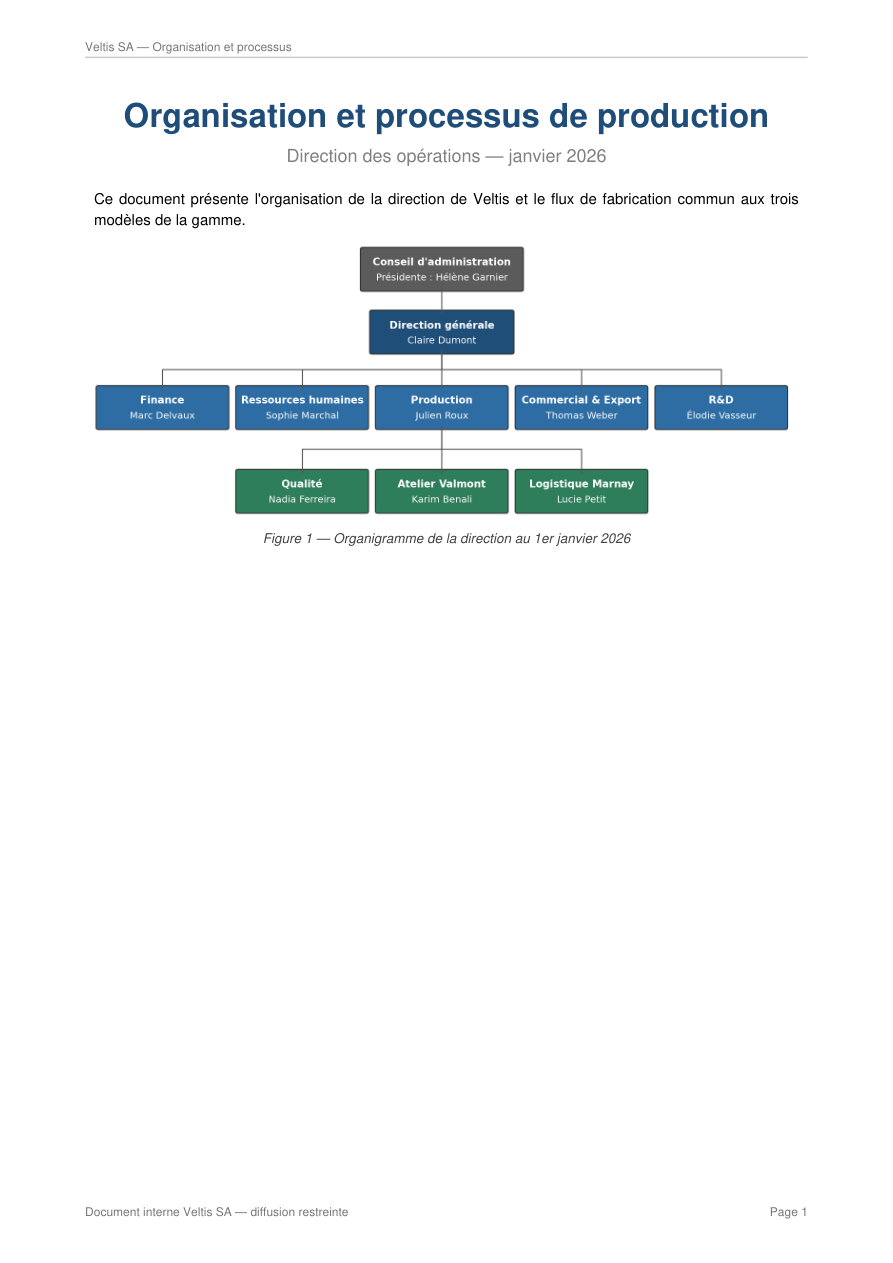


=== ORIGINAL PDF — PAGE 2 ===


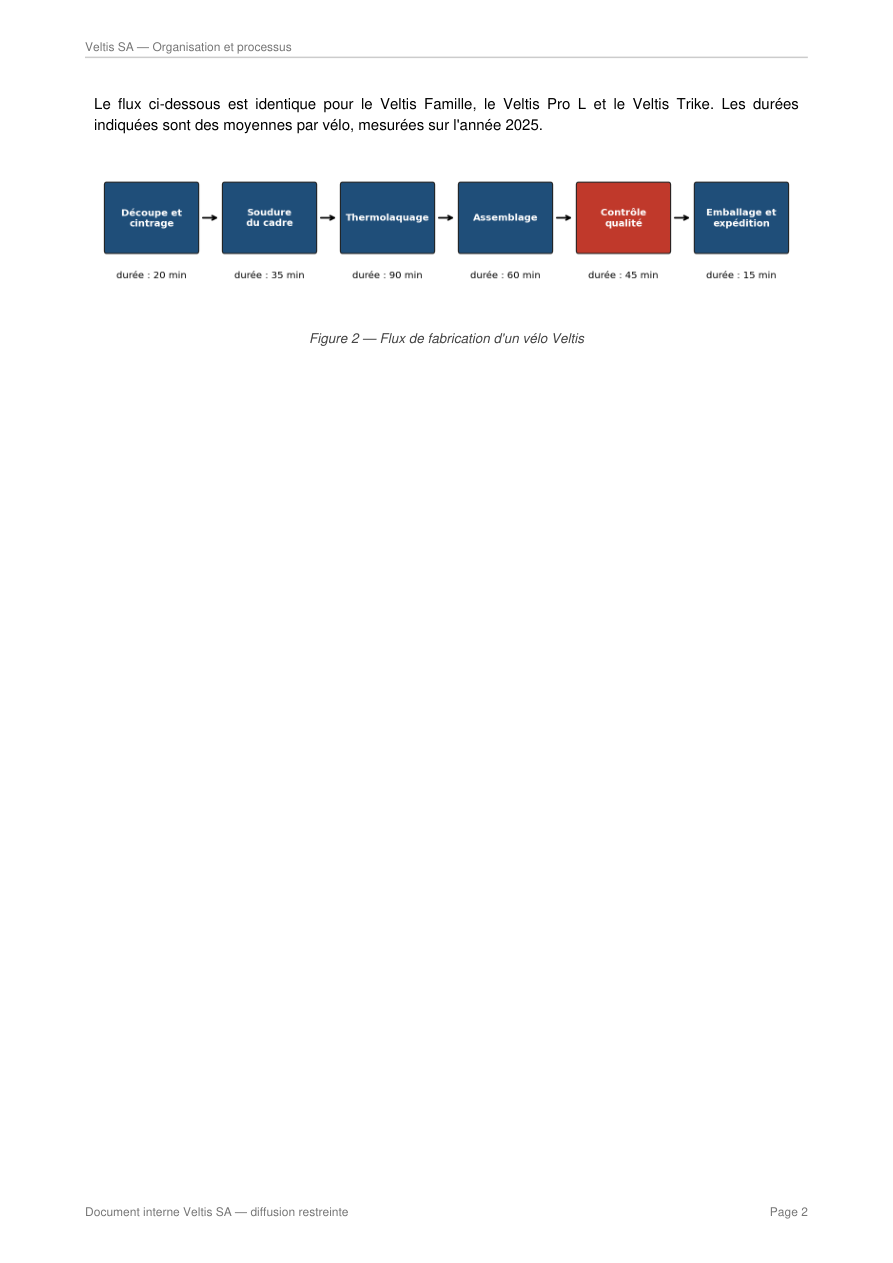


E3.9 — PDF DISPLAY COMPLETED


In [ ]:
# ============================================================
# E3.9 — VISUAL VERIFICATION OF THE ORIGINAL PDF
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Display the original PDF pages for visual verification.
#
# SAFEGUARDS:
#   - Read-only operation.
#   - No OCR or document reprocessing.
#   - No changes to PostgreSQL or Qdrant.
# ============================================================

from pathlib import Path
import fitz
from IPython.display import display, Image

pdf_path = (
    PROJECT_ROOT
    / "data/veltis"
    / "organigramme_et_processus_production.pdf"
)

assert pdf_path.is_file(), "Original PDF not found."

# Open the PDF without modifying it.
with fitz.open(pdf_path) as pdf:

    assert len(pdf) == 2, "Unexpected number of pages."

    for page_number in range(len(pdf)):

        page = pdf[page_number]

        # Render at 150% for easier reading.
        pixmap = page.get_pixmap(
            matrix=fitz.Matrix(1.5, 1.5)
        )

        print(f"\n=== ORIGINAL PDF — PAGE {page_number + 1} ===")

        display(
            Image(data=pixmap.tobytes("png"))
        )

print("\nE3.9 — PDF DISPLAY COMPLETED")

In [ ]:
# ============================================================
# E3.9.1 — CONFIRM VISUAL VERIFICATION
#
# Update verification metadata for the two enriched passages.
# No changes to Qdrant or PostgreSQL.
# ============================================================

for passage in enriched_passages:
    passage["verification_status"] = "visually_verified"

# Verify the update.
assert all(
    p["verification_status"] == "visually_verified"
    for p in enriched_passages
)

print("=== E3.9.1 — VERIFICATION STATUS ===")

for passage in enriched_passages:
    print(
        f"Page {passage['page']} | "
        f"{passage['figure']} | "
        f"{passage['verification_status']}"
    )

print("\nE3.9.1 — SUCCESS")

=== E3.9.1 — VERIFICATION STATUS ===
Page 1 | Figure 1 — Organigramme | visually_verified
Page 2 | Figure 2 — Flux de fabrication | visually_verified

E3.9.1 — SUCCESS


In [ ]:
# ============================================================
# E3.10.1 — CREATE SAFE EXPERIMENTAL QDRANT COLLECTION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Prepare a separate collection for enriched documents.
#
# SAFEGUARDS:
#   - Never modify or delete the reference collection.
#   - Never recreate an existing experimental collection.
#   - Preserve dense and sparse vector configurations.
#   - Do not insert any points yet.
# ============================================================

from copy import deepcopy

# 1. Define collection names.
REFERENCE_COLLECTION = "veltis_hybrid_100_20261014"
EXPERIMENT_COLLECTION = "veltis_hybrid_enriched_test_20261015"

assert REFERENCE_COLLECTION != EXPERIMENT_COLLECTION

# 2. Verify the reference collection.
assert qclient.collection_exists(REFERENCE_COLLECTION), (
    "Reference collection does not exist."
)

reference_info = qclient.get_collection(REFERENCE_COLLECTION)

# 3. Verify baseline data.
reference_count = qclient.count(
    collection_name=REFERENCE_COLLECTION,
    exact=True
).count

assert reference_count == 129, (
    f"Unexpected baseline count: {reference_count}"
)

# 4. Read existing vector configurations.
dense_config = deepcopy(
    reference_info.config.params.vectors
)

sparse_config = deepcopy(
    reference_info.config.params.sparse_vectors
)

assert "dense" in dense_config
assert "sparse" in sparse_config

# 5. Create the experimental collection if absent.
if qclient.collection_exists(EXPERIMENT_COLLECTION):

    print("Experimental collection already exists.")
    print("Action: Existing collection preserved.")

else:

    qclient.create_collection(
        collection_name=EXPERIMENT_COLLECTION,
        vectors_config=dense_config,
        sparse_vectors_config=sparse_config
    )

    print("Experimental collection created.")

# 6. Verify both collections.
experiment_info = qclient.get_collection(EXPERIMENT_COLLECTION)

experiment_count = qclient.count(
    collection_name=EXPERIMENT_COLLECTION,
    exact=True
).count

assert qclient.count(
    collection_name=REFERENCE_COLLECTION,
    exact=True
).count == 129

print("\n=== E3.10.1 — COLLECTION STATUS ===")
print("Reference:", REFERENCE_COLLECTION)
print("Reference points:", reference_count)
print("Experiment:", EXPERIMENT_COLLECTION)
print("Experiment points:", experiment_count)

print("\nE3.10.1 — SUCCESS")

Experimental collection created.

=== E3.10.1 — COLLECTION STATUS ===
Reference: veltis_hybrid_100_20261014
Reference points: 129
Experiment: veltis_hybrid_enriched_test_20261015
Experiment points: 0

E3.10.1 — SUCCESS


In [ ]:
# ============================================================
# E3.10.2 — COPY BASELINE POINTS TO EXPERIMENTAL COLLECTION
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Copy all 129 baseline Qdrant points, including:
#   - Point IDs
#   - Dense vectors
#   - Sparse vectors
#   - Document metadata
#   - Chunk text
#
# SAFEGUARDS:
#   - Read-only access to reference collection.
#   - Never delete or recreate collections.
#   - Never overwrite existing experimental points.
#   - Preserve original point identifiers.
#   - Verify the copy after completion.
# ============================================================

from qdrant_client import models

# 1. Verify reference collection.
assert qclient.collection_exists(REFERENCE_COLLECTION)
assert qclient.collection_exists(EXPERIMENT_COLLECTION)

reference_count_before = qclient.count(
    collection_name=REFERENCE_COLLECTION,
    exact=True
).count

assert reference_count_before == 129

# 2. Load all reference points, including vectors.
baseline_points = []
offset = None

while True:

    points, offset = qclient.scroll(
        collection_name=REFERENCE_COLLECTION,
        limit=100,
        offset=offset,
        with_payload=True,
        with_vectors=True
    )

    baseline_points.extend(points)

    if offset is None:
        break

assert len(baseline_points) == reference_count_before

# 3. Check which points are already present in the experiment.
existing_ids = set()
offset = None

while True:

    points, offset = qclient.scroll(
        collection_name=EXPERIMENT_COLLECTION,
        limit=100,
        offset=offset,
        with_payload=False,
        with_vectors=False
    )

    existing_ids.update(str(point.id) for point in points)

    if offset is None:
        break

# 4. Prepare only missing points.
points_to_copy = []

for point in baseline_points:

    if str(point.id) in existing_ids:
        continue

    assert point.vector is not None, (
        f"Missing vectors for point {point.id}"
    )

    points_to_copy.append(
        models.PointStruct(
            id=point.id,
            vector=point.vector,
            payload=point.payload or {}
        )
    )

print("=== E3.10.2 — COPY PREPARATION ===")
print("Reference points:", len(baseline_points))
print("Already present:", len(existing_ids))
print("Points to copy:", len(points_to_copy))

# 5. Copy missing points in small batches.
BATCH_SIZE = 25

for start in range(0, len(points_to_copy), BATCH_SIZE):

    batch = points_to_copy[start:start + BATCH_SIZE]

    qclient.upsert(
        collection_name=EXPERIMENT_COLLECTION,
        points=batch,
        wait=True
    )

    print(
        f"Copied {min(start + BATCH_SIZE, len(points_to_copy))}"
        f"/{len(points_to_copy)} missing points"
    )

# 6. Verify final counts.
reference_count_after = qclient.count(
    collection_name=REFERENCE_COLLECTION,
    exact=True
).count

experiment_count = qclient.count(
    collection_name=EXPERIMENT_COLLECTION,
    exact=True
).count

assert reference_count_after == reference_count_before, (
    "Reference collection count changed."
)

assert experiment_count >= reference_count_before, (
    "Experimental collection contains fewer than 129 points."
)

# Verify that every baseline point ID exists in the experiment.
experiment_ids = set()
offset = None

while True:

    points, offset = qclient.scroll(
        collection_name=EXPERIMENT_COLLECTION,
        limit=100,
        offset=offset,
        with_payload=False,
        with_vectors=False
    )

    experiment_ids.update(str(point.id) for point in points)

    if offset is None:
        break

baseline_ids = {str(point.id) for point in baseline_points}

assert baseline_ids.issubset(experiment_ids), (
    "Some baseline point IDs are missing from the experiment."
)

print("\n=== E3.10.2 — COPY VERIFICATION ===")
print("Reference points:", reference_count_after)
print("Experimental points:", experiment_count)
print("Baseline IDs preserved:", len(baseline_ids))
print("Missing baseline IDs:", len(baseline_ids - experiment_ids))

print("\nE3.10.2 — SUCCESS")

=== E3.10.2 — COPY PREPARATION ===
Reference points: 129
Already present: 0
Points to copy: 129
Copied 25/129 missing points
Copied 50/129 missing points
Copied 75/129 missing points
Copied 100/129 missing points
Copied 125/129 missing points
Copied 129/129 missing points

=== E3.10.2 — COPY VERIFICATION ===
Reference points: 129
Experimental points: 129
Baseline IDs preserved: 129
Missing baseline IDs: 0

E3.10.2 — SUCCESS


In [ ]:
# ============================================================
# E3.10.3 — INDEX ENRICHED PASSAGES IN QDRANT
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Add two visually verified passages to the experiment.
#
# SAFEGUARDS:
#   - Reference collection remains unchanged.
#   - Deterministic UUIDs prevent duplicate insertion.
#   - Existing point IDs are checked before writing.
#   - Preserve document provenance and verification status.
# ============================================================

import uuid
from qdrant_client import models

# 1. Verify prerequisites.
assert qclient.collection_exists(EXPERIMENT_COLLECTION)

assert len(enriched_passages) == 2

assert all(
    p["verification_status"] == "visually_verified"
    for p in enriched_passages
), "Visual verification is required."

# 2. Verify the baseline.
reference_count = qclient.count(
    collection_name=REFERENCE_COLLECTION,
    exact=True
).count

assert reference_count == 129

# 3. Prepare the new points.
enriched_points = []

for passage in enriched_passages:

    text = passage["text"]

    # Generate a deterministic identifier.
    # The same source, page and figure produce the same UUID.
    point_id = str(
        uuid.uuid5(
            uuid.NAMESPACE_URL,
            (
                "veltis-enriched-v1:"
                + passage["source_document"]
                + ":"
                + str(passage["page"])
                + ":"
                + passage["figure"]
            )
        )
    )

    # Generate the dense vector using the existing BGE-M3 server.
    dense_vector = embedding_client.embeddings.create(
        model="bge-m3",
        input=text
    ).data[0].embedding

    assert len(dense_vector) == 1024

    # The sparse representation uses the same BM25 model
    # already configured for our hybrid Qdrant collection.
    enriched_points.append(
        models.PointStruct(
            id=point_id,
            vector={
                "dense": dense_vector,
                "sparse": models.Document(
                    text=text,
                    model="qdrant/bm25"
                )
            },
            payload={
                "dataset": "veltis",
                "chunk_profile": "enriched_diagram",
                "file_name": passage["source_document"],
                "global_index": 1000 + passage["page"],
                "text": text,
                "page": passage["page"],
                "figure": passage["figure"],
                "extraction_method": passage["extraction_method"],
                "verification_status": passage["verification_status"]
            }
        )
    )

# 4. Check existing IDs to prevent accidental overwrites.
point_ids = [point.id for point in enriched_points]

existing_points = qclient.retrieve(
    collection_name=EXPERIMENT_COLLECTION,
    ids=point_ids,
    with_payload=True,
    with_vectors=False
)

existing_ids = {str(point.id) for point in existing_points}

new_points = [
    point for point in enriched_points
    if str(point.id) not in existing_ids
]

print("=== E3.10.3 — INDEXING PREPARATION ===")
print("Enriched passages:", len(enriched_points))
print("Already indexed:", len(existing_ids))
print("New points:", len(new_points))

# 5. Insert only missing points.
if new_points:

    qclient.upsert(
        collection_name=EXPERIMENT_COLLECTION,
        points=new_points,
        wait=True
    )

# 6. Verify the experiment.
experiment_count = qclient.count(
    collection_name=EXPERIMENT_COLLECTION,
    exact=True
).count

reference_count_after = qclient.count(
    collection_name=REFERENCE_COLLECTION,
    exact=True
).count

assert reference_count_after == 129, (
    "Reference collection count changed."
)

assert experiment_count == 131, (
    f"Expected 131 experimental points, found {experiment_count}."
)

print("\n=== E3.10.3 — INDEXING RESULTS ===")
print("Reference points:", reference_count_after)
print("Experimental points:", experiment_count)
print("Enriched points:", experiment_count - reference_count_after)

print("\nE3.10.3 — SUCCESS")

=== E3.10.3 — INDEXING PREPARATION ===
Enriched passages: 2
Already indexed: 0
New points: 2

=== E3.10.3 — INDEXING RESULTS ===
Reference points: 129
Experimental points: 131
Enriched points: 2

E3.10.3 — SUCCESS


In [ ]:
# ============================================================
# E3.11 — COMPARE BASELINE VS ENRICHED RETRIEVAL
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Compare Q15 and Q16 on two Qdrant collections.
#
# SAFEGUARDS:
#   - Read-only searches.
#   - Same embeddings and retrieval parameters.
#   - No PostgreSQL modifications.
#   - No changes to existing collections.
# ============================================================

from qdrant_client import models
import time

comparison_results = []

# 1. Select the two questions.
test_questions = [
    q for q in evaluation_dataset
    if q["id"] in ("Q15", "Q16")
]

assert len(test_questions) == 2

# 2. Compare both collections.
for item in test_questions:

    question = item["question"]
    expected_docs = set(item["expected_documents"])

    # Generate the question embedding only once.
    query_vector = embedding_client.embeddings.create(
        model="bge-m3",
        input=question
    ).data[0].embedding

    for collection in (
        REFERENCE_COLLECTION,
        EXPERIMENT_COLLECTION
    ):

        start = time.perf_counter()

        results = qclient.query_points(
            collection_name=collection,
            prefetch=[
                models.Prefetch(
                    query=query_vector,
                    using="dense",
                    limit=PREFETCH_LIMIT
                ),
                models.Prefetch(
                    query=models.Document(
                        text=question,
                        model="qdrant/bm25"
                    ),
                    using="sparse",
                    limit=PREFETCH_LIMIT
                )
            ],
            query=models.RrfQuery(
                rrf=models.Rrf(
                    k=RRF_K,
                    weights=RRF_WEIGHTS
                )
            ),
            limit=TOP_K,
            with_payload=True
        )

        search_ms = (
            time.perf_counter() - start
        ) * 1000

        retrieved = []

        for rank, point in enumerate(results.points, start=1):

            payload = point.payload or {}

            retrieved.append({
                "rank": rank,
                "document": payload.get("file_name"),
                "chunk": payload.get("global_index"),
                "profile": payload.get("chunk_profile"),
                "text": payload.get("text", ""),
                "score": point.score
            })

        # Rank of first expected document.
        first_rank = next(
            (
                p["rank"]
                for p in retrieved
                if p["document"] in expected_docs
            ),
            None
        )

        comparison_results.append({
            "id": item["id"],
            "collection": collection,
            "first_relevant_rank": first_rank,
            "hit_at_1": first_rank == 1,
            "hit_at_5": first_rank is not None,
            "search_ms": search_ms,
            "passages": retrieved
        })

# 3. Display comparison.
print("=== E3.11 — RETRIEVAL COMPARISON ===")

for row in comparison_results:

    print("\nQuestion:", row["id"])
    print("Collection:", row["collection"])
    print("First relevant rank:", row["first_relevant_rank"])
    print("Hit@1:", row["hit_at_1"])
    print("Hit@5:", row["hit_at_5"])
    print(f"Search time: {row['search_ms']:.0f} ms")

    for passage in row["passages"]:

        print(
            f"  [{passage['rank']}] "
            f"{passage['document']} | "
            f"{passage['profile']} | "
            f"{passage['text'][:120]}"
        )

print("\nE3.11 — COMPARISON COMPLETED")

=== E3.11 — RETRIEVAL COMPARISON ===

Question: Q15
Collection: veltis_hybrid_100_20261014
First relevant rank: None
Hit@1: False
Hit@5: False
Search time: 14 ms
  [1] intranet_faq_rh.html | 100 | FAQ Ressources humaines
Contacts du service RH
Paie et avantages, Personne de contact = Léa Fontaine. Paie et avantages,
  [2] newsletter_le_fil_2026-02.pdf | 100 | Retour sur la journée portes ouvertes
Ce mois-ci, nous accueillons sept nouvelles personnes : trois en assemblage, deux 
  [3] newsletter_le_fil_2026-02.pdf | 100 | Portrait : Karim Benali, douze ans d'atelier
Entré chez Veltis comme soudeur en 2014, Karim dirige aujourd'hui l'atelier
  [4] guide_onboarding.pdf | 100 | 4.2 Découverte des services
Durant la première semaine, vous passerez une demi-journée dans au moins deux services diffé
  [5] guide_onboarding.pdf | 100 | 6. Contacts utiles
Question RH, contrat, congés, Contact = Service RH. Question RH, contrat, congés, Poste = 2000. Infor

Question: Q15
Collection: veltis_hybrid

In [ ]:
# ============================================================
# E3.12 — FULL RETRIEVAL REGRESSION TEST
# Project: RAG Veltis → TechReg
#
# PURPOSE:
#   Compare baseline and enriched collections on 22 questions.
#
# METRICS:
#   - Document Hit@1
#   - Document Hit@5
#   - First relevant document rank
#   - Retrieval latency
#   - Improved and regressed questions
#
# SAFEGUARDS:
#   - Read-only Qdrant queries.
#   - Reuse existing baseline evaluation.
#   - No LLM generation.
#   - No collection or PostgreSQL modifications.
# ============================================================

import time
import statistics
from qdrant_client import models

# 1. Verify prerequisites.
assert len(evaluation_dataset) == 22
assert len(retrieval_evaluation) == 22

assert qclient.collection_exists(EXPERIMENT_COLLECTION)

# 2. Map original evaluation results by question ID.
baseline_map = {
    row["id"]: row
    for row in retrieval_evaluation
}

# 3. Evaluate the enriched collection.
enriched_evaluation = []

for item in evaluation_dataset:

    question_id = item["id"]
    question = item["question"]
    expected_docs = set(item["expected_documents"])

    # Measure embedding + Qdrant retrieval, as in E3.1.
    start = time.perf_counter()

    query_vector = embedding_client.embeddings.create(
        model="bge-m3",
        input=question
    ).data[0].embedding

    results = qclient.query_points(
        collection_name=EXPERIMENT_COLLECTION,
        prefetch=[
            models.Prefetch(
                query=query_vector,
                using="dense",
                limit=PREFETCH_LIMIT
            ),
            models.Prefetch(
                query=models.Document(
                    text=question,
                    model="qdrant/bm25"
                ),
                using="sparse",
                limit=PREFETCH_LIMIT
            )
        ],
        query=models.RrfQuery(
            rrf=models.Rrf(
                k=RRF_K,
                weights=RRF_WEIGHTS
            )
        ),
        limit=TOP_K,
        with_payload=True
    )

    retrieval_ms = (
        time.perf_counter() - start
    ) * 1000

    retrieved_docs = [
        (point.payload or {}).get("file_name")
        for point in results.points
    ]

    first_rank = next(
        (
            rank
            for rank, doc in enumerate(retrieved_docs, start=1)
            if doc in expected_docs
        ),
        None
    )

    enriched_evaluation.append({
        "id": question_id,
        "question": question,
        "expected_documents": sorted(expected_docs),
        "retrieved_documents": retrieved_docs,
        "first_relevant_rank": first_rank,
        "hit_at_1": (
            int(first_rank == 1) if expected_docs else None
        ),
        "hit_at_5": (
            int(first_rank is not None) if expected_docs else None
        ),
        "retrieval_ms": retrieval_ms
    })

# 4. Compare results question by question.
print("=== E3.12 — BASELINE VS ENRICHED ===")
print("ID  | Baseline rank | Enriched rank | Change")
print("-" * 52)

improved = []
regressed = []

for row in enriched_evaluation:

    qid = row["id"]

    baseline = baseline_map[qid]
    old_rank = baseline["first_relevant_rank"]
    new_rank = row["first_relevant_rank"]

    if qid == "Q22":
        change = "NO EXPECTED DOCUMENT"

    elif old_rank is None and new_rank is not None:
        change = "IMPROVED"
        improved.append(qid)

    elif old_rank is not None and new_rank is None:
        change = "REGRESSED"
        regressed.append(qid)

    elif old_rank is not None and new_rank is not None:

        if new_rank < old_rank:
            change = "IMPROVED"
            improved.append(qid)

        elif new_rank > old_rank:
            change = "REGRESSED"
            regressed.append(qid)

        else:
            change = "UNCHANGED"

    else:
        change = "UNCHANGED"

    print(
        f"{qid} | "
        f"{str(old_rank):>13} | "
        f"{str(new_rank):>13} | "
        f"{change}"
    )

# 5. Calculate aggregate metrics.
answerable = [
    row for row in enriched_evaluation
    if row["hit_at_1"] is not None
]

hit1 = sum(row["hit_at_1"] for row in answerable)
hit5 = sum(row["hit_at_5"] for row in answerable)

mean_latency = statistics.mean(
    row["retrieval_ms"]
    for row in enriched_evaluation
)

# 6. Display the summary.
print("\n=== E3.12 — ENRICHED RETRIEVAL SUMMARY ===")

print("Questions evaluated:", len(enriched_evaluation))

print(
    f"Document Hit@1: {hit1}/{len(answerable)} "
    f"({hit1 / len(answerable):.1%})"
)

print(
    f"Document Hit@5: {hit5}/{len(answerable)} "
    f"({hit5 / len(answerable):.1%})"
)

print(f"Average retrieval latency: {mean_latency:.0f} ms")

print("Improved questions:", improved)
print("Regressed questions:", regressed)

print("\nE3.12 — SUCCESS")